# GKD optimizer × parameterization — `20260801_optparam_160m`

End-to-end analysis of the completed **E8 × E11** campaign
(optimizer × parameterization factorial) on run-set
**`20260801_optparam_160m`**. Teachers: `sdf_teachers/20260726_crossinit_160m`.
Pre-registration: `docs/PREREG_OPTPARAM.md`. Plan:
`.cursor/plans/optimizer_parameterization_campaign_c092f671.plan.md`.

This notebook is **read-only** on cached outputs. It consumes
`results/*.csv` + `claims.json` plus the campaign log JSONs under `logs/`
(calibration, LR selection, control floor, quarantine, state). It does **not**
re-derive `subliminal_delta` from raw preference leaves (prereg §3 Finalize).

**Literature frame.** Blank et al. Fig. 7b/7c omit per-optimizer LRs; Appendix L /
Fig. 19 is a two-sentence loss-match with an 18% gap. Our figures supply the
ladder Blank omitted, a 2×4 heatmap at screened LRs, loss-matched pairs where
feasible, and probe trajectories in the spirit of their Fig. 2.

**Run from the repo root:**
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_optimizer_parameterization.ipynb` and run all cells
top-to-bottom. Paths resolve from `configs/paths/paths_local.yaml` via
`analysis.setup.bootstrap` — never hardcode SSD roots.


## Setup


In [43]:
from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import print_scope, short_model
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import optparam_plan as plan
from subliminal_learning.gkd.layout import optim_slug

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

RUN_SET_ID = plan.RUN_SET_ID
TEACHER_RUN_SET_ID = plan.TEACHER_RUN_SET_ID
SUBDIR = f"gkd_students/{RUN_SET_ID}"
TREE = OUTPUT_ROOT / SUBDIR
RES = TREE / "results"
LOGS = TREE / "logs"

assert TREE.exists(), f"expected run tree missing: {TREE}"
assert RES.exists(), f"expected results/ missing: {RES}"
assert not str(TREE).startswith("/mnt/ssd-1"), (
    "use output_root path (SSD-2), never hardcode /mnt/ssd-1"
)
if TREE.is_symlink():
    print("WARNING: tree is a symlink (possibly cold-archive); loads may be slow")

print("ROOT         :", ROOT)
print("OUTPUT_ROOT  :", OUTPUT_ROOT)
print("TREE         :", TREE)
print("RUN_SET_ID   :", RUN_SET_ID)
print("plan constants: animals=", plan.ANIMALS, "inits=", plan.INITS)
print("  PHASE0_MAX_STEPS=", plan.PHASE0_MAX_STEPS,
      "LOSS_MATCH_TOL=", plan.LOSS_MATCH_TOL,
      "CONTROL_FLOOR_MAX=", plan.CONTROL_FLOOR_MAX,
      "CONTROL_FLOOR_MAX_SPREAD=", plan.CONTROL_FLOOR_MAX_SPREAD)
print("  CLAIM_MIN_INITS=", plan.CLAIM_MIN_INITS,
      "SGD_NULL_EQUIVALENCE_FRACTION=", plan.SGD_NULL_EQUIVALENCE_FRACTION)
print("  PRIMARY_PROMPT_SET=", plan.PRIMARY_PROMPT_SET,
      "PRIMARY_SCORING=", plan.PRIMARY_SCORING)


ROOT         : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
OUTPUT_ROOT  : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
TREE         : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260801_optparam_160m
RUN_SET_ID   : 20260801_optparam_160m
plan constants: animals= ('cat', 'dog') inits= ('original', 'data-seed1', 'weight-seed1')
  PHASE0_MAX_STEPS= 625 LOSS_MATCH_TOL= 0.1 CONTROL_FLOOR_MAX= 0.02 CONTROL_FLOOR_MAX_SPREAD= 0.01
  CLAIM_MIN_INITS= 2 SGD_NULL_EQUIVALENCE_FRACTION= 0.05
  PRIMARY_PROMPT_SET= test PRIMARY_SCORING= prob


In [44]:
# --- load persisted results + campaign logs (read-only) ---

def _read_json(path: Path) -> dict | list:
    return json.loads(path.read_text())


run_set = _read_json(TREE / "run_set.json")
campaign_done_txt = (LOGS / plan.CAMPAIGN_DONE_FILE).read_text().strip()
campaign_state = _read_json(LOGS / plan.CAMPAIGN_STATE_FILE)
calib = _read_json(LOGS / plan.CALIBRATION_REPORT)
lr_sel = _read_json(LOGS / plan.LR_SELECTION_REPORT)
floor_rep = _read_json(LOGS / plan.CONTROL_FLOOR_REPORT)
quarantine_rep = _read_json(LOGS / plan.QUARANTINE_REPORT)
claims_doc = _read_json(RES / plan.RESULTS_CLAIMS_JSON)

delta_raw = pd.read_csv(RES / plan.RESULTS_DELTA_CSV)
delta_agg_raw = pd.read_csv(RES / plan.RESULTS_DELTA_AGG_CSV)
loss_match = pd.read_csv(RES / plan.RESULTS_LOSS_MATCH_CSV)
probes = pd.read_csv(RES / plan.RESULTS_PROBE_CSV)
grads = pd.read_csv(RES / plan.RESULTS_GRAD_CSV)
quarantine = pd.read_csv(RES / plan.RESULTS_QUARANTINE_CSV)

SELECTED_LRS: dict[str, float] = {
    k: float(v) for k, v in claims_doc["selected_lrs"].items()
}
PRIMARY = plan.PRIMARY_PROMPT_SET

# Capability join in build_results can triplicate identical delta rows that differ
# only in perplexity_ratio (one per student gseed). Deduplicate before any claim
# recomputation so n_inits_positive is not inflated 3×.
_DELTA_KEYS = [
    "arm", "parameterization", "student_optim", "optim_momentum",
    "animal", "init", "student_lr", "set", "gkd_tag", "tier", "flag_reasons",
]


def _dedupe_delta(df: pd.DataFrame) -> pd.DataFrame:
    num = [
        "subliminal_delta", "ci_lower", "ci_upper", "n_pairs",
        "p_target_treatment", "p_target_control", "perplexity_ratio",
    ]
    ag = {c: "first" for c in df.columns if c not in num and c not in _DELTA_KEYS}
    ag.update({c: "mean" for c in num if c in df.columns})
    out = (
        df.groupby(_DELTA_KEYS, dropna=False)
        .agg(ag)
        .reset_index()
    )
    return out


delta = _dedupe_delta(delta_raw)
print(
    f"delta_raw={len(delta_raw)} → deduped={len(delta)} "
    f"(dropped {len(delta_raw) - len(delta)} capability-join duplicates)"
)

# Rebuild aggregate from deduped delta (matches pipeline math, without dup inflation).
_rows = delta.copy()
_rows["ci_width"] = _rows["ci_upper"] - _rows["ci_lower"]
_rows["ci_positive"] = (_rows["ci_lower"] > 0).astype(int)
_AGG = [
    "set", "arm", "parameterization", "student_optim", "optim_momentum",
    "animal", "student_lr", "tier", "flag_reasons",
]
delta_agg = (
    _rows.groupby(_AGG, dropna=False)
    .agg(
        subliminal_delta=("subliminal_delta", "mean"),
        delta_min=("subliminal_delta", "min"),
        delta_max=("subliminal_delta", "max"),
        ci_lower_min=("ci_lower", "min"),
        ci_upper_max=("ci_upper", "max"),
        mean_ci_width=("ci_width", "mean"),
        n_inits=("init", "nunique"),
        n_inits_positive=("ci_positive", "sum"),
        perplexity_ratio=("perplexity_ratio", "mean"),
    )
    .reset_index()
)

# Compare on-disk agg (may be dup-inflated) vs recomputed.
print(
    f"delta_agg_raw n_inits_positive max={delta_agg_raw['n_inits_positive'].max()} | "
    f"recomputed max={delta_agg['n_inits_positive'].max()}"
)

ARM_ORDER = [a.key for a in plan.ARMS]
PARAM_ORDER = list(plan.PARAMETERIZATIONS)
OPTIM_ORDER = list(plan.OPTIM_SLUGS)
INIT_ORDER = [
    "pythia-160m",
    "pythia-160m-data-seed1",
    "pythia-160m-weight-seed1",
]


def arm_slug(arm: str) -> str:
    # full_adamw -> adamw; lora_sgdm0.9 -> sgdm0.9
    return arm.split("_", 1)[1]


def is_selected_lr(arm: str, lr: float) -> bool:
    return math.isclose(float(lr), float(SELECTED_LRS[arm]), rel_tol=0.0, abs_tol=0.0)


def print_opt_scope(df: pd.DataFrame, note: str = "") -> None:
    # Scope line for optparam columns (init / gseed / tfs when present).
    bits = [f"{len(df)} rows"]
    for col, label in [
        ("animal", "animals"),
        ("arm", "arms"),
        ("init", "inits"),
        ("gseed", "gseeds"),
        ("teacher_ftseed", "tfs"),
        ("student_lr", "lrs"),
        ("set", "sets"),
        ("tier", "tiers"),
    ]:
        if col in df.columns:
            bits.append(f"{df[col].nunique(dropna=True)} {label}")
    line = "SCOPE: " + " | ".join(bits)
    if note:
        line += f" | {note}"
    print(line)


print("Loaded CSVs:")
for name, df in [
    ("delta", delta),
    ("delta_agg", delta_agg),
    ("loss_match", loss_match),
    ("probes", probes),
    ("grads", grads),
    ("quarantine", quarantine),
]:
    print(f"  {name:12s} {df.shape}")
print("CAMPAIGN_DONE:", campaign_done_txt)
print("claims prompt_set/scoring:", claims_doc.get("prompt_set"), claims_doc.get("scoring"))
print("selected_lrs:", SELECTED_LRS)


delta_raw=1188 → deduped=612 (dropped 576 capability-join duplicates)
delta_agg_raw n_inits_positive max=9 | recomputed max=3
Loaded CSVs:
  delta        (612, 18)
  delta_agg    (372, 18)
  loss_match   (692, 18)
  probes       (10576, 38)
  grads        (294, 39)
  quarantine   (31, 13)
CAMPAIGN_DONE: campaign 20260801_optparam_160m finished 2026-08-02T22:31:07Z
claims prompt_set/scoring: test prob
selected_lrs: {'full_adamw': 1e-05, 'full_rmsprop': 2e-05, 'full_sgd': 0.1, 'full_sgdm0.9': 0.01, 'lora_adamw': 0.0002, 'lora_rmsprop': 0.0002, 'lora_sgd': 0.1, 'lora_sgdm0.9': 0.01}


## 0. Campaign provenance and identity

Identity constants come from `optparam_plan.py` and on-disk `run_set.json` /
`logs/campaign_state.json`. Phase-0 was amended from a **200-step** screen to a
**625-step** screen (campaign dose); the superseded queue lives under
`logs/superseded_s200_screen/` and must not be mixed into loss-matching.


In [45]:
identity = pd.DataFrame(
    [
        ("run_set_id", run_set.get("run_set_id"), plan.RUN_SET_ID),
        ("teacher_run_set_id", run_set.get("teacher_run_set_id"), plan.TEACHER_RUN_SET_ID),
        ("git_sha", run_set.get("git_sha"), "(from run_set.json)"),
        ("model_size", run_set.get("model_size"), "160m"),
        ("teacher workflow/mode", f"{plan.TEACHER_WORKFLOW}/{plan.TEACHER_MODE}", ""),
        ("teacher LoRA tag", plan.TEACHER_PARAM_TAG_LORA, ""),
        ("beta / lmbda / epochs", f"{plan.BETA}/{plan.LMBDA}/{plan.NUM_EPOCHS}", ""),
        ("prompt pool", plan.PROMPT_POOL_DIR, ""),
        ("primary metric", f"subliminal_delta on set={PRIMARY} scoring={plan.PRIMARY_SCORING}", ""),
        ("inits", ", ".join(plan.INITS), ""),
        ("tfs headline / gseeds", f"{plan.TFS_HEADLINE} / {plan.GSEEDS}", ""),
        ("W&B corner", f"tfs={plan.WANDB_CORNER_TFS}, gseed={plan.WANDB_CORNER_GSEED} only in Phase 2", ""),
    ],
    columns=["field", "on_disk_or_plan", "plan_constant"],
)
display(identity)

print("\nTransitions:")
for name, payload in campaign_state.get("transitions", {}).items():
    at = payload.get("at") if isinstance(payload, dict) else None
    extra = []
    if isinstance(payload, dict):
        for k in ("n_cells", "quarantined", "dropped_arms", "lossmatch_yamls"):
            if k in payload:
                extra.append(f"{k}={payload[k]}")
    print(f"  {name:12s} at={at}  " + " ".join(extra))

print("\nNotes:")
for n in campaign_state.get("notes", []):
    print(" ", n)

superseded = LOGS / "superseded_s200_screen"
print("\nsuperseded_s200_screen present:", superseded.exists())
if superseded.exists():
    n_files = sum(1 for _ in superseded.rglob("*") if _.is_file())
    print(f"  files under superseded tree: {n_files}")
    print("  (ignored by calibrate_arms via PHASE0_MAX_STEPS filter)")

# 2×4 arm table from plan
arm_rows = []
for a in plan.ARMS:
    arm_rows.append(
        {
            "arm": a.key,
            "mode": a.mode,
            "optim_slug": a.optim_slug,
            "HF optim": a.optim,
            "momentum": a.momentum,
            "selected_lr": SELECTED_LRS.get(a.key),
        }
    )
display(pd.DataFrame(arm_rows))


,field,on_disk_or_plan,plan_constant
0,run_set_id,20260801_optparam_160m,20260801_optparam_160m
1,teacher_run_set_id,20260726_crossinit_160m,20260726_crossinit_160m
2,git_sha,96dccbb62c07d57f52d1ad66cbc4ae6823fc3b81,(from run_set.json)
3,model_size,160m,160m
4,teacher workflow/mode,sdf/lora,
5,teacher LoRA tag,ep5_lr5e-5_r128a128,
6,beta / lmbda / epochs,1.0/1.0/1.0,
7,prompt pool,gkd_prompts/pile_prompts_v1,
8,primary metric,subliminal_delta on set=test scoring=prob,
9,inits,"original, data-seed1, weight-seed1",



Transitions:
  submit_p0    at=2026-08-01T07:32:39Z  n_cells=49
  submit_p1    at=2026-08-01T09:23:33Z  
  submit_p2    at=2026-08-02T00:30:44Z  quarantined=[{'arm': 'lora_sgdm0.9', 'lr': 0.1}] dropped_arms=[] lossmatch_yamls=['gkd_op_p2lm_full_adamw.yaml', 'gkd_op_p2lm_lora_adamw.yaml']
  finalize     at=2026-08-02T22:31:07Z  

Notes:
  2026-08-01: Phase-0 re-screened at PHASE0_MAX_STEPS=625 (the campaign dose). The 200-step screen left both sgdm0.9 arms still descending and so mis-read the loss-match gate; its queue records, state and configs are under logs/superseded_s200_screen/. Leaves tagged _s200_ remain on disk and are ignored by the new same-budget filter in optparam_selection._cell.

superseded_s200_screen present: True
  files under superseded tree: 160
  (ignored by calibrate_arms via PHASE0_MAX_STEPS filter)


,arm,mode,optim_slug,HF optim,momentum,selected_lr
0,lora_adamw,lora-r8a16,adamw,adamw_torch,0.0,0.00020
1,lora_rmsprop,lora-r8a16,rmsprop,rmsprop,0.0,0.00020
2,lora_sgd,lora-r8a16,sgd,sgd,0.0,0.10000
3,lora_sgdm0.9,lora-r8a16,sgdm0.9,sgd,0.9,0.01000
4,full_adamw,full,adamw,adamw_torch,0.0,0.00001
5,full_rmsprop,full,rmsprop,rmsprop,0.0,0.00002
6,full_sgd,full,sgd,sgd,0.0,0.10000
7,full_sgdm0.9,full,sgdm0.9,sgd,0.9,0.01000


**W&B caveat.** Phase 0 logs every cell; Phase 2 logs only the corner
`(SCREEN_INIT, tfs=1, gseed=0)` per headline arm; everything else uses
`--no-wandb`. Absence of a W&B run is not evidence a cell was skipped.


## 1. Inventory, coverage, and imbalance audit

Cell counts vs plan constants. Seed axes:

| Axis | Meaning | Values |
|---|---|---|
| **init** | student (+ teacher) base PolyPythia variant | `original`, `data-seed1`, `weight-seed1` |
| **tfs** | teacher fine-tune seed | 0, 1, 2 (headline); loss-match tier uses tfs 0 only |
| **gseed** | student GKD seed | 0, 1, 2 |

`optparam_delta` rows are **already paired over gseed** (and average teacher
ftseed within the lineage) via `subliminal_delta_ci`. They are **not**
per-(tfs×gseed) leaf deltas — see § seed robustness.


In [46]:
print("=== Plan cell budgets ===")
print(f"  PHASE0_CELLS (625-step screen): {plan.PHASE0_CELLS}")
print(f"  PHASE1 treatments / controls: {plan.PHASE1_TREATMENT_CELLS} / {plan.PHASE1_CONTROL_CELLS}")
print(f"  PHASE2 treatments (headline): {plan.PHASE2_TREATMENT_CELLS}")
print(f"  PHASE2 max loss-match / controls: "
      f"{plan.PHASE2_MAX_LOSSMATCH_CELLS} / {plan.PHASE2_MAX_CONTROL_CELLS}")

# loss_match leaf census (treatments only; includes Phase-0 s200+s625)
lm = loss_match.copy()
print("\n=== loss_match max_steps census (treatment leaves) ===")
print(lm["max_steps"].value_counts(dropna=False).to_string())
print("\nBy arm × max_steps:")
print(
    lm.assign(ms=lm["max_steps"].fillna(-1))
    .groupby(["arm", "ms"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

# Epoch-budget leaves (Phase 1/2): max_steps NaN
lm_e = lm[lm["max_steps"].isna()].copy()
print_opt_scope(lm_e, "Phase 1/2 epoch-budget treatment leaves in loss_match")

# Headline coverage at selected LR (deduped delta, test)
d_test = delta[delta["set"] == PRIMARY].copy()
head = d_test[d_test.apply(lambda r: is_selected_lr(r["arm"], r["student_lr"]), axis=1)]
print_opt_scope(head, "headline selected-LR × test (deduped)")
print(head.groupby(["arm", "animal"])["init"].nunique().unstack(fill_value=0))

# Expected Phase-1 ladder grid on screen init only: n_inits==1 in agg
p1_like = delta_agg[
    (delta_agg["set"] == PRIMARY) & (delta_agg["n_inits"] == 1)
].copy()
print_opt_scope(p1_like, "agg rows with n_inits=1 (Phase-1 screen init)")
print("Phase-1-like (arm, lr) counts:")
print(p1_like.groupby("arm")["student_lr"].nunique().to_string())

# Quarantine / advisory census
print("\n=== Quarantine CSV tier counts ===")
print(quarantine["tier"].value_counts(dropna=False).to_string())
q_bad = quarantine[quarantine["tier"] != "ok"]
display(q_bad[[
    "arm", "lr", "tier", "reasons", "control_floor",
    "n_treatment_diverged", "control_diverged", "treatment_ppl", "control_ppl",
]])

# Imbalance: missing (arm, animal, init) at selected LR
expected = []
for arm in ARM_ORDER:
    for animal in plan.ANIMALS:
        for init in INIT_ORDER:
            expected.append((arm, animal, init))
have = set(zip(head["arm"], head["animal"], head["init"]))
missing = [t for t in expected if t not in have]
print(f"\nHeadline missing (arm, animal, init): {len(missing)}")
if missing:
    print(pd.DataFrame(missing, columns=["arm", "animal", "init"]).to_string(index=False))
else:
    print("  (none — full 8×2×3 grid present at selected LRs)")

# Phase-1 rung gaps: lora_sgd has 3 ladder rungs (usable range only 3)
print("\nPhase-0 → Phase-1 ladders (from calibration report):")
for a in calib["arms"]:
    print(
        f"  {a['arm']:14s} phase1_ladder={a['phase1_ladder']} "
        f"usable={a['usable_range']} infeas={a['lossmatch_infeasible']}"
    )


=== Plan cell budgets ===
  PHASE0_CELLS (625-step screen): 49
  PHASE1 treatments / controls: 192 / 64
  PHASE2 treatments (headline): 432
  PHASE2 max loss-match / controls: 144 / 288

=== loss_match max_steps census (treatment leaves) ===
max_steps
NaN      594
200.0     49
625.0     49

By arm × max_steps:
ms            -1.0     200.0   625.0
arm                                 
full_adamw        84       6       6
full_rmsprop      72       6       6
full_sgd          72       6       6
full_sgdm0.9      72       6       6
lora_adamw        84       6       6
lora_rmsprop      72       6       6
lora_sgd          66       7       7
lora_sgdm0.9      72       6       6
SCOPE: 594 rows | 2 animals | 8 arms | 3 inits | 3 gseeds | 3 tfs | 12 lrs | Phase 1/2 epoch-budget treatment leaves in loss_match
SCOPE: 48 rows | 2 animals | 8 arms | 3 inits | 5 lrs | 1 sets | 2 tiers | headline selected-LR × test (deduped)
animal        cat  dog
arm                   
full_adamw      3    3
full_

,arm,lr,tier,reasons,control_floor,n_treatment_diverged,control_diverged,treatment_ppl,control_ppl
0,full_adamw,0.000002,advisory,edge_of_usable_range,0.006597,0,False,5.036974e+01,3.842441e+01
7,full_rmsprop,0.000020,advisory,edge_of_usable_range,0.006450,0,False,6.017083e+01,4.154959e+01
8,full_sgd,0.000100,advisory,edge_of_usable_range,0.005892,0,False,3.796256e+01,3.775466e+01
11,full_sgd,0.100000,advisory,edge_of_usable_range,0.003553,0,False,6.029555e+01,4.640604e+01
12,full_sgdm0.9,0.000010,advisory,edge_of_usable_range,0.006207,0,False,3.795742e+01,3.791208e+01
15,full_sgdm0.9,0.010000,advisory,edge_of_usable_range,0.006069,0,False,6.097400e+01,4.335238e+01
16,lora_adamw,0.000050,advisory,edge_of_usable_range,0.008785,0,False,5.466194e+01,3.957817e+01
20,lora_rmsprop,0.000025,advisory,edge_of_usable_range,0.009697,0,False,5.130411e+01,3.894798e+01
24,lora_sgd,0.001000,advisory,edge_of_usable_range,0.006091,0,False,3.786171e+01,3.792927e+01
26,lora_sgd,0.100000,advisory,edge_of_usable_range,0.005188,0,False,5.456019e+01,4.256702e+01



Headline missing (arm, animal, init): 0
  (none — full 8×2×3 grid present at selected LRs)

Phase-0 → Phase-1 ladders (from calibration report):
  full_adamw     phase1_ladder=[2e-06, 5e-06, 1e-05, 2e-05] usable=[2e-06, 5e-05] infeas=False
  full_rmsprop   phase1_ladder=[2e-06, 5e-06, 1e-05, 2e-05] usable=[1e-06, 2e-05] infeas=False
  full_sgd       phase1_ladder=[0.0001, 0.001, 0.01, 0.1] usable=[0.0001, 0.1] infeas=True
  full_sgdm0.9   phase1_ladder=[1e-05, 0.0001, 0.001, 0.01] usable=[1e-05, 0.01] infeas=True
  lora_adamw     phase1_ladder=[5e-05, 0.0001, 0.0002, 0.0004] usable=[5e-05, 0.0008] infeas=False
  lora_rmsprop   phase1_ladder=[2.5e-05, 5e-05, 0.0001, 0.0002] usable=[2.5e-05, 0.0004] infeas=False
  lora_sgd       phase1_ladder=[0.001, 0.01, 0.1] usable=[0.001, 0.1] infeas=True
  lora_sgdm0.9   phase1_ladder=[0.0001, 0.001, 0.01, 0.1] usable=[0.0001, 0.1] infeas=True


## 2. Phase-0 calibration — LR ladder and loss match

Reference: `lora/adamw` @ `4e-4` (frozen Stage-A recipe). Tolerance band
`|loss − loss_ref| / loss_ref ≤ LOSS_MATCH_TOL` from `optparam_plan`. Excluded /
diverged rungs are shown, not dropped. Four SGD-family arms are
`lossmatch_infeasible` (no rung reaches the reference loss).


reference_arm=lora/adamw lr=0.0004 final_train_loss=0.248944 max_steps=625
tolerance=0.1 → band [0.224050, 0.273839]
lossmatch_infeasible_arms: ['full_sgd', 'full_sgdm0.9', 'lora_sgd', 'lora_sgdm0.9']
SCOPE: 49 rows | 8 arms | Phase-0 calibration rungs (625-step)


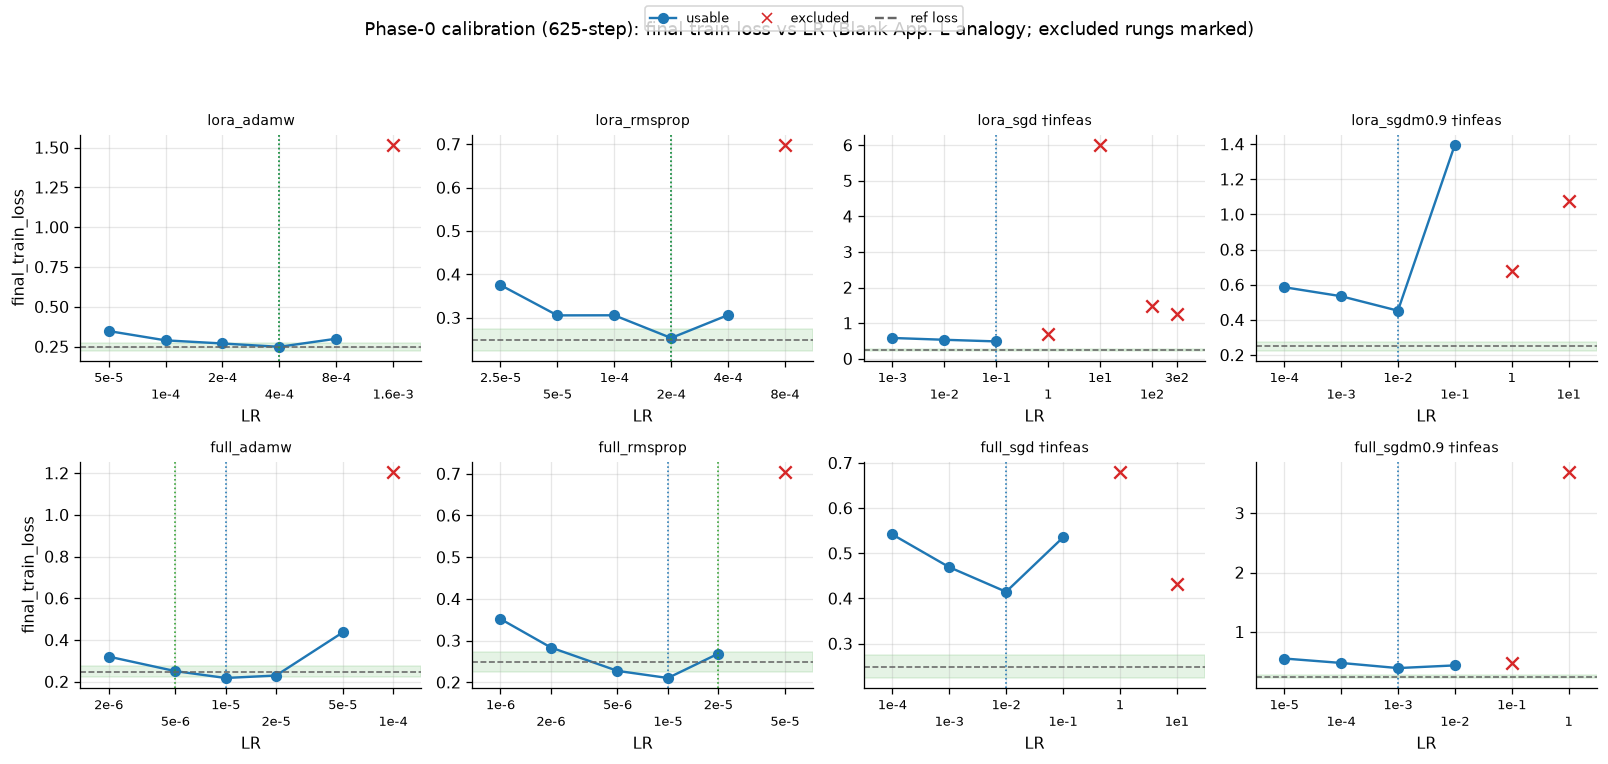

,arm,lr_best,lr_lossmatch,lossmatch_infeasible,lossmatch_closest_lr,lossmatch_rel_error,usable_lo,usable_hi,n_excluded,exclusion_reasons
0,full_adamw,0.00001,0.000005,False,0.000005,0.007685,0.000002,0.00005,1,probe ppl 277.2 exceeds ceiling 180.3
1,full_rmsprop,0.00001,0.000020,False,0.000020,0.079559,0.000001,0.00002,1,probe ppl 6.332e+18 exceeds ceiling 180.3
2,full_sgd,0.01000,NaN,True,0.010000,0.666287,0.000100,0.10000,2,probe ppl 2.013e+18 exceeds ceiling 180.3; pro...
3,full_sgdm0.9,0.00100,NaN,True,0.001000,0.570583,0.000010,0.01000,2,probe trajectory flagged diverged
4,lora_adamw,0.00040,0.000400,False,0.000400,0.000000,0.000050,0.00080,1,probe ppl 216.8 exceeds ceiling 180.3
5,lora_rmsprop,0.00020,0.000200,False,0.000200,0.018572,0.000025,0.00040,1,probe trajectory flagged diverged
6,lora_sgd,0.10000,NaN,True,0.100000,0.958557,0.001000,0.10000,4,probe ppl 1.166e+09 exceeds ceiling 180.3; pro...
7,lora_sgdm0.9,0.01000,NaN,True,0.010000,0.816707,0.000100,0.10000,2,probe ppl 3.897e+23 exceeds ceiling 180.3; pro...


Write-up rule: for lossmatch_infeasible arms, report 'no rung reaches the reference loss' — never quote the nearest miss as matched.


In [47]:
ref_loss = float(calib["reference_final_train_loss"])
tol = float(calib["loss_match_tolerance"])
assert math.isclose(tol, plan.LOSS_MATCH_TOL)
band_lo, band_hi = ref_loss * (1 - tol), ref_loss * (1 + tol)
print(
    f"reference_arm={calib['reference_arm']} lr={calib['reference_lr']} "
    f"final_train_loss={ref_loss:.6f} max_steps={calib['max_steps']}"
)
print(f"tolerance={tol} → band [{band_lo:.6f}, {band_hi:.6f}]")
print("lossmatch_infeasible_arms:", calib["lossmatch_infeasible_arms"])

# Long frame of every Phase-0 rung
p0_rows = []
for a in calib["arms"]:
    for r in a["rungs"]:
        p0_rows.append(
            {
                "arm": a["arm"],
                "lr": r["lr"],
                "final_train_loss": r["final_train_loss"],
                "ppl": r["ppl"],
                "p_target": r["p_target"],
                "excluded": r["excluded"],
                "exclusion_reason": r["exclusion_reason"],
                "lr_best": a["lr_best"],
                "lr_lossmatch": a["lr_lossmatch"],
                "lossmatch_infeasible": a["lossmatch_infeasible"],
                "lossmatch_rel_error": a["lossmatch_rel_error"],
            }
        )
p0 = pd.DataFrame(p0_rows)
print_opt_scope(p0, "Phase-0 calibration rungs (625-step)")


def _lr_tick(v: float) -> str:
    """Compact scientific LR label: 2.5e-5, 1e-4, 1, 3e2."""
    v = float(v)
    if v <= 0 or not np.isfinite(v):
        return ""
    exp = int(np.floor(np.log10(v)))
    mant = v / (10.0 ** exp)
    if np.isclose(mant, 1.0, rtol=0.0, atol=1e-12):
        return "1" if exp == 0 else f"1e{exp}"
    if np.isclose(mant, round(mant), rtol=0.0, atol=1e-8):
        return f"{int(round(mant))}e{exp}"
    return f"{mant:g}e{exp}"


fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharey=False)
axes = axes.ravel()
for i, arm in enumerate(ARM_ORDER):
    ax = axes[i]
    sub = p0[p0["arm"] == arm].sort_values("lr")
    ok = sub[~sub["excluded"]]
    bad = sub[sub["excluded"]]
    if len(ok):
        ax.plot(ok["lr"], ok["final_train_loss"], "o-", color="C0", label="usable")
    if len(bad):
        ax.scatter(
            bad["lr"], bad["final_train_loss"].fillna(np.nan),
            marker="x", s=60, color="C3", label="excluded", zorder=5,
        )
        # If loss is nan, plot at top of usable range for visibility
        for _, row in bad.iterrows():
            y = row["final_train_loss"]
            if y is None or (isinstance(y, float) and not np.isfinite(y)):
                y = float(ok["final_train_loss"].max()) * 1.05 if len(ok) else 1.0
                ax.scatter([row["lr"]], [y], marker="x", s=60, color="C3")
                ax.annotate(
                    "non-finite/div",
                    (row["lr"], y),
                    fontsize=7,
                    color="C3",
                    xytext=(4, 4),
                    textcoords="offset points",
                )
    ax.axhline(ref_loss, color="0.4", ls="--", lw=1, label="ref loss")
    ax.axhspan(band_lo, band_hi, color="C2", alpha=0.12, label="±10% band")
    # mark lr_best / lr_lossmatch
    ab = sub.iloc[0]
    if ab["lr_best"] is not None and not (isinstance(ab["lr_best"], float) and np.isnan(ab["lr_best"])):
        ax.axvline(ab["lr_best"], color="C0", ls=":", lw=1)
    if ab["lr_lossmatch"] is not None and not (
        isinstance(ab["lr_lossmatch"], float) and np.isnan(ab["lr_lossmatch"])
    ):
        ax.axvline(ab["lr_lossmatch"], color="C2", ls=":", lw=1)
    ax.set_xscale("log")
    lrs = np.asarray(sub["lr"], dtype=float)
    ax.set_xticks(lrs)
    ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
    labs = [_lr_tick(v) for v in lrs]
    labs = [lab if i % 2 == 0 else f"\n{lab}" for i, lab in enumerate(labs)]
    ax.set_xticklabels(labs, rotation=0, ha="center", fontsize=8)
    for tick in ax.get_xticklabels():
        tick.set_clip_on(False)
    lo, hi = float(np.min(lrs)), float(np.max(lrs))
    pad = 3.0 if lo == hi else (hi / lo) ** 0.10
    ax.set_xlim(lo / pad, hi * pad)
    ax.set_title(arm + (" †infeas" if ab["lossmatch_infeasible"] else ""), fontsize=9)
    ax.set_xlabel("LR")
    if i % 4 == 0:
        ax.set_ylabel("final_train_loss")
handles = [
    Line2D([0], [0], marker="o", color="C0", label="usable"),
    Line2D([0], [0], marker="x", color="C3", linestyle="None", label="excluded"),
    Line2D([0], [0], color="0.4", ls="--", label="ref loss"),
]
fig.legend(handles=handles, loc="upper center", ncol=4, fontsize=8)
fig.suptitle(
    "Phase-0 calibration (625-step): final train loss vs LR "
    "(Blank App. L analogy; excluded rungs marked)",
    fontsize=11,
)
fig.tight_layout(rect=[0, 0.05, 1, 0.93], w_pad=0.9, h_pad=1.0)
plt.show()

# Summary table
summary = []
for a in calib["arms"]:
    summary.append(
        {
            "arm": a["arm"],
            "lr_best": a["lr_best"],
            "lr_lossmatch": a["lr_lossmatch"],
            "lossmatch_infeasible": a["lossmatch_infeasible"],
            "lossmatch_closest_lr": a["lossmatch_closest_lr"],
            "lossmatch_rel_error": a["lossmatch_rel_error"],
            "usable_lo": a["usable_range"][0],
            "usable_hi": a["usable_range"][1],
            "n_excluded": sum(1 for r in a["rungs"] if r["excluded"]),
            "exclusion_reasons": "; ".join(
                sorted({r["exclusion_reason"] for r in a["rungs"] if r["excluded"]})
            ),
        }
    )
display(pd.DataFrame(summary))
print(
    "Write-up rule: for lossmatch_infeasible arms, report "
    "'no rung reaches the reference loss' — never quote the nearest miss as matched."
)


## 3. Gate history — control floor and quarantine

Phase-1 amendment (`PREREG_OPTPARAM.md` §8): per-rung tiers `ok` / `advisory` /
`quarantine` replace a binary campaign halt. Quarantined rungs stay on disk as
evidence but are excluded from LR selection and Phase-2.


control_floor_report: passed=True max_floor=0.02 max_spread=0.01 failures=[]
SCOPE: 60 rows | 2 animals | 8 arms | 12 lrs | control-floor active (non-skipped) rows
max floor_p_target=0.0109 (threshold 0.02); max spread=0.0059 (threshold 0.01)


,arm,animal,floor_min,floor_max,n_rungs,spread
11,lora_rmsprop,dog,0.005090,0.010948,4,0.005858
9,lora_adamw,dog,0.004910,0.010448,4,0.005537
5,full_sgd,dog,0.003553,0.007633,4,0.004080
1,full_adamw,dog,0.006597,0.010209,4,0.003612
3,full_rmsprop,dog,0.006450,0.009003,4,0.002553
7,full_sgdm0.9,dog,0.005965,0.008224,4,0.002260
13,lora_sgd,dog,0.005188,0.006788,3,0.001600
0,full_adamw,cat,0.001630,0.002721,4,0.001091
2,full_rmsprop,cat,0.001677,0.002476,4,0.000799
4,full_sgd,cat,0.001608,0.002337,4,0.000729



Skipped floor rows (quarantined rungs):


,animal,beta,student_mode,student_optim,optim_momentum,student_lr,floor_p_target,skipped,arm
30,cat,1.0,lora,sgd,0.9,0.1,1.333064e-25,True,lora_sgdm0.9
61,dog,1.0,lora,sgd,0.9,0.1,1.816315e-03,True,lora_sgdm0.9


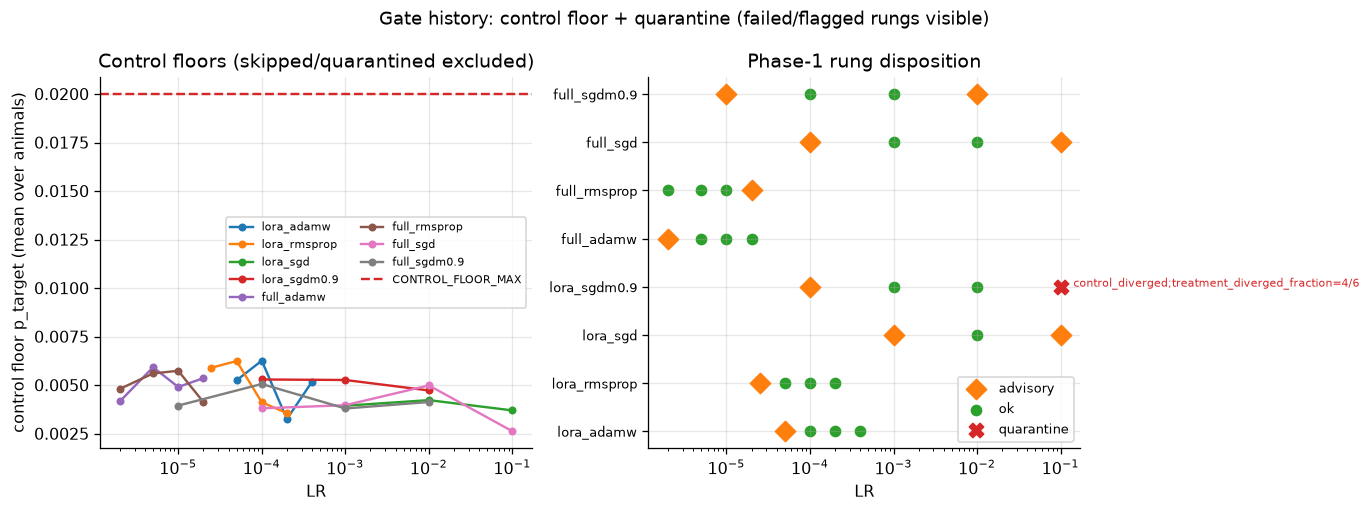


Flagged / quarantined rungs (cost to headline):


,arm,selected_lr,tier_at_selected,reasons,quarantined_elsewhere
0,full_adamw,0.00001,ok,NaN,[]
1,full_rmsprop,0.00002,advisory,edge_of_usable_range,[]
2,full_sgd,0.10000,advisory,edge_of_usable_range,[]
3,full_sgdm0.9,0.01000,advisory,edge_of_usable_range,[]
4,lora_adamw,0.00020,ok,NaN,[]
5,lora_rmsprop,0.00020,ok,NaN,[]
6,lora_sgd,0.10000,advisory,edge_of_usable_range,[]
7,lora_sgdm0.9,0.01000,ok,NaN,[0.1]


Notable: lora_sgdm0.9 @ 0.1 is QUARANTINE (control_diverged; 4/6 treatments diverged). Headline LR moved 0.1 → 0.01 (weaker claim — amendment §8).


In [48]:
print(
    f"control_floor_report: passed={floor_rep['passed']} "
    f"max_floor={floor_rep['max_floor']} max_spread={floor_rep['max_spread']} "
    f"failures={floor_rep['failures']}"
)
assert floor_rep["max_floor"] == plan.CONTROL_FLOOR_MAX
assert floor_rep["max_spread"] == plan.CONTROL_FLOOR_MAX_SPREAD

floors = pd.DataFrame(floor_rep["floors"])


def _floor_arm(row) -> str:
    kind = "full" if row["student_mode"] == "full" else "lora"
    slug = optim_slug(str(row["student_optim"]), float(row["optim_momentum"] or 0.0))
    return f"{kind}_{slug}"


floors["arm"] = floors.apply(_floor_arm, axis=1)
active = floors[~floors["skipped"]].copy()
skipped = floors[floors["skipped"]].copy()

spread = (
    active.groupby(["arm", "animal"])["floor_p_target"]
    .agg(floor_min="min", floor_max="max", n_rungs="count")
    .reset_index()
)
spread["spread"] = spread["floor_max"] - spread["floor_min"]
print_opt_scope(active, "control-floor active (non-skipped) rows")
print(
    f"max floor_p_target={active['floor_p_target'].max():.4f} "
    f"(threshold {plan.CONTROL_FLOOR_MAX}); "
    f"max spread={spread['spread'].max():.4f} "
    f"(threshold {plan.CONTROL_FLOOR_MAX_SPREAD})"
)
display(spread.sort_values("spread", ascending=False))

print("\nSkipped floor rows (quarantined rungs):")
display(skipped)

# Visual: floors + quarantine flags
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: floor by arm×lr (mean over animals)
ax = axes[0]
plot_f = active.copy()
for arm in ARM_ORDER:
    sub = plot_f[plot_f["arm"] == arm]
    if sub.empty:
        continue
    g = sub.groupby("student_lr")["floor_p_target"].mean().sort_index()
    ax.plot(g.index, g.values, "o-", label=arm, ms=4)
ax.axhline(plan.CONTROL_FLOOR_MAX, color="C3", ls="--", label="CONTROL_FLOOR_MAX")
ax.set_xscale("log")
ax.set_xlabel("LR")
ax.set_ylabel("control floor p_target (mean over animals)")
ax.set_title("Control floors (skipped/quarantined excluded)")
ax.legend(fontsize=7, ncol=2)

# Right: quarantine tiers
ax = axes[1]
q = quarantine.copy()
tier_color = {"ok": "C2", "advisory": "C1", "quarantine": "C3"}
for tier, sub in q.groupby("tier"):
    ax.scatter(
        sub["lr"],
        sub["arm"].map({a: i for i, a in enumerate(ARM_ORDER)}),
        c=tier_color.get(tier, "C0"),
        label=tier,
        s=80 if tier != "ok" else 40,
        marker="X" if tier == "quarantine" else ("D" if tier == "advisory" else "o"),
        zorder=3 if tier != "ok" else 1,
    )
ax.set_yticks(range(len(ARM_ORDER)))
ax.set_yticklabels(ARM_ORDER, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("LR")
ax.set_title("Phase-1 rung disposition")
ax.legend(fontsize=8)
# annotate the quarantine
qq = q[q["tier"] == "quarantine"]
for _, row in qq.iterrows():
    ax.annotate(
        str(row["reasons"])[:48],
        (row["lr"], ARM_ORDER.index(row["arm"])),
        fontsize=7,
        color="C3",
        xytext=(8, 0),
        textcoords="offset points",
    )

fig.suptitle("Gate history: control floor + quarantine (failed/flagged rungs visible)", fontsize=11)
fig.tight_layout()
plt.show()

print("\nFlagged / quarantined rungs (cost to headline):")
flagged = q[q["tier"] != "ok"].copy()
# Did selection avoid quarantined?
sel_rows = []
for arm, lr in SELECTED_LRS.items():
    match = q[q["arm"] == arm]
    match = match[np.isclose(match["lr"].astype(float), float(lr))]
    tier = match["tier"].iloc[0] if len(match) else "?"
    reasons = match["reasons"].iloc[0] if len(match) else ""
    sel_rows.append(
        {
            "arm": arm,
            "selected_lr": lr,
            "tier_at_selected": tier,
            "reasons": reasons,
            "quarantined_elsewhere": list(
                q[(q["arm"] == arm) & (q["tier"] == "quarantine")]["lr"]
            ),
        }
    )
display(pd.DataFrame(sel_rows))
print(
    "Notable: lora_sgdm0.9 @ 0.1 is QUARANTINE "
    "(control_diverged; 4/6 treatments diverged). "
    "Headline LR moved 0.1 → 0.01 (weaker claim — amendment §8)."
)


## 4. Phase-1 LR ladder dose-response (Blank Fig. 7b/7c omitted this)

Primary metric: `subliminal_delta` on `test`. One line per arm, faceted by
animal. Quarantined rungs marked with ×. CIs are the paired multi-seed intervals
already in `optparam_delta` (after dedupe), averaged across inits present at
that rung (Phase-1 = screen init only for most rungs).


SCOPE: 62 rows | 2 animals | 8 arms | 1 inits | 12 lrs | 1 sets | 3 tiers | Phase-1 ladder dose-response (init=pythia-160m-data-seed1, set=test)


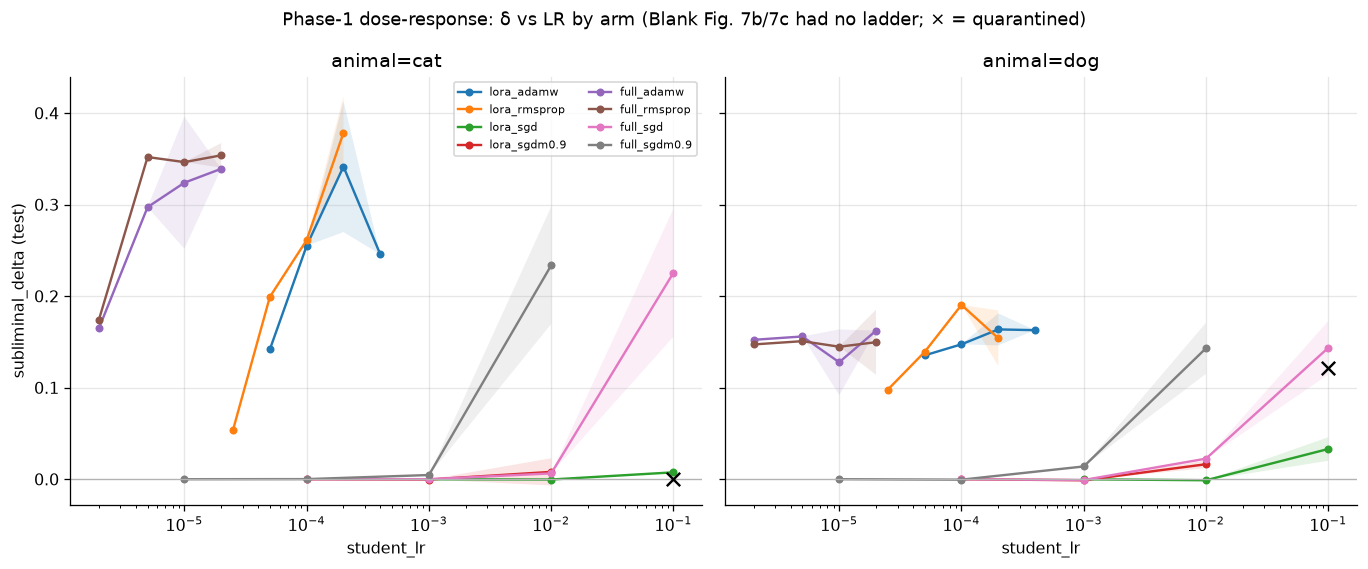

,arm,selected_lr,mean_delta,lr_lossmatch,needs_lossmatch_arm
0,full_adamw,0.00001,0.245383,0.000005,True
1,full_rmsprop,0.00002,0.261663,0.000020,False
2,full_sgd,0.10000,0.201559,NaN,False
3,full_sgdm0.9,0.01000,0.220912,NaN,False
4,lora_adamw,0.00020,0.235791,0.000400,True
5,lora_rmsprop,0.00020,0.243803,0.000200,False
6,lora_sgd,0.10000,0.026448,NaN,False
7,lora_sgdm0.9,0.01000,0.008696,NaN,False


In [49]:
# Phase-1-like: use deduped delta on test where init is screen init OR n_pairs from screen
screen_init_model = "pythia-160m-data-seed1"
ladder = delta[
    (delta["set"] == PRIMARY) & (delta["init"] == screen_init_model)
].copy()
print_opt_scope(
    ladder,
    f"Phase-1 ladder dose-response (init={screen_init_model}, set={PRIMARY})",
)

# Merge quarantine tier for markers
q_key = quarantine[["arm", "lr", "tier"]].rename(columns={"lr": "student_lr", "tier": "q_tier"})
ladder = ladder.merge(q_key, on=["arm", "student_lr"], how="left")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, animal in zip(axes, plan.ANIMALS):
    sub = ladder[ladder["animal"] == animal]
    for arm in ARM_ORDER:
        a = sub[sub["arm"] == arm].sort_values("student_lr")
        if a.empty:
            continue
        ok = a[a["q_tier"] != "quarantine"]
        bad = a[a["q_tier"] == "quarantine"]
        if len(ok):
            ax.plot(ok["student_lr"], ok["subliminal_delta"], "o-", label=arm, ms=4)
            ax.fill_between(
                ok["student_lr"],
                ok["ci_lower"],
                ok["ci_upper"],
                alpha=0.12,
            )
        if len(bad):
            ax.scatter(
                bad["student_lr"],
                bad["subliminal_delta"],
                marker="x",
                s=70,
                c="k",
                zorder=5,
                label=None,
            )
    ax.axhline(0, color="0.7", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("student_lr")
    ax.set_title(f"animal={animal}")
    ax.set_ylabel("subliminal_delta (test)" if animal == "cat" else "")
axes[0].legend(fontsize=7, ncol=2, loc="best")
fig.suptitle(
    "Phase-1 dose-response: δ vs LR by arm "
    "(Blank Fig. 7b/7c had no ladder; × = quarantined)",
    fontsize=11,
)
fig.tight_layout()
plt.show()

# Also show selection means from lr_selection_report
sel_tbl = pd.DataFrame(lr_sel["arms"])
display(sel_tbl[["arm", "selected_lr", "mean_delta", "lr_lossmatch", "needs_lossmatch_arm"]])


## 5. Phase-2 headline 2×4 heatmap

At each arm's **selected LR**, mean `subliminal_delta` over inits (recomputed
agg). Cells boxed when the paired CI does **not** clear zero on ≥
`CLAIM_MIN_INITS` inits for that animal (control not cleared). Annotations show
mean δ and `[ci_lower_min, ci_upper_max]`.


SCOPE: 16 rows | 2 animals | 8 arms | 5 lrs | 1 sets | 2 tiers | headline agg at selected LRs


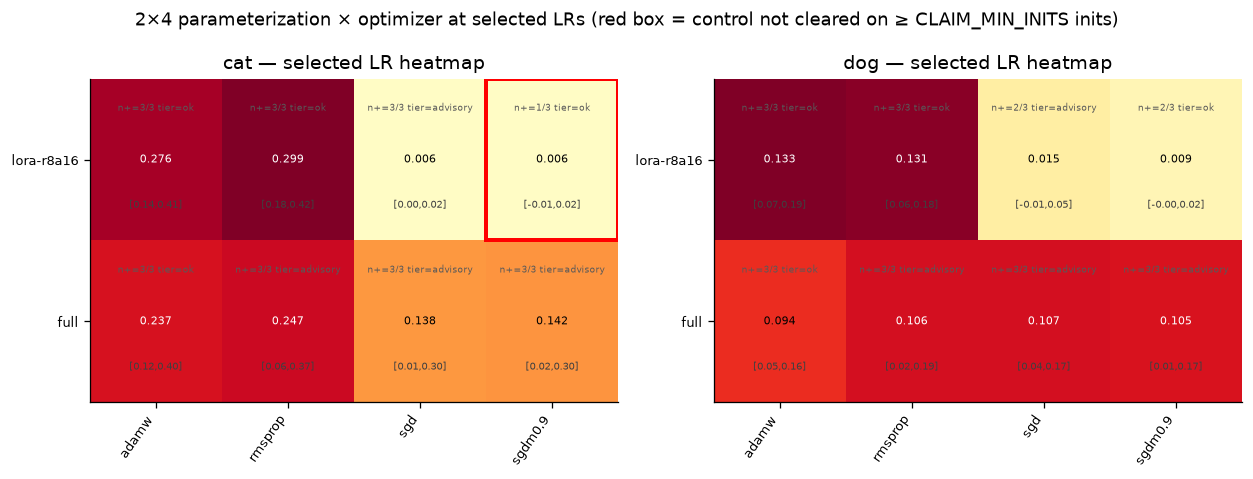

,arm,animal,student_lr,subliminal_delta,ci_lower_min,ci_upper_max,mean_ci_width,n_inits,n_inits_positive,tier,flag_reasons
250,full_adamw,cat,0.00001,0.237111,0.118191,0.396166,0.089864,3,3,ok,NaN
254,full_adamw,dog,0.00001,0.093976,0.047130,0.163725,0.059458,3,3,ok,NaN
259,full_rmsprop,cat,0.00002,0.247016,0.056533,0.367343,0.122810,3,3,advisory,edge_of_usable_range
263,full_rmsprop,dog,0.00002,0.106381,0.020471,0.185257,0.095269,3,3,advisory,edge_of_usable_range
267,full_sgd,cat,0.10000,0.138290,0.009736,0.295505,0.136993,3,3,advisory,edge_of_usable_range
271,full_sgd,dog,0.10000,0.106702,0.039886,0.172801,0.063062,3,3,advisory,edge_of_usable_range
275,full_sgdm0.9,cat,0.01000,0.142017,0.022432,0.297714,0.123871,3,3,advisory,edge_of_usable_range
279,full_sgdm0.9,dog,0.01000,0.104613,0.009295,0.171031,0.110518,3,3,advisory,edge_of_usable_range
282,lora_adamw,cat,0.00020,0.275644,0.143617,0.413064,0.101075,3,3,ok,NaN
286,lora_adamw,dog,0.00020,0.133276,0.072462,0.188364,0.064820,3,3,ok,NaN


In [50]:
head_agg = delta_agg[
    (delta_agg["set"] == PRIMARY)
    & delta_agg.apply(lambda r: is_selected_lr(r["arm"], r["student_lr"]), axis=1)
].copy()
print_opt_scope(head_agg, "headline agg at selected LRs")

# Build grids: rows=parameterization, cols=optim slug
def _pivot_metric(animal: str, col: str) -> pd.DataFrame:
    sub = head_agg[head_agg["animal"] == animal].copy()
    sub["param"] = sub["parameterization"]
    sub["optim"] = sub["arm"].map(arm_slug)
    grid = (
        sub.pivot_table(index="param", columns="optim", values=col, observed=True)
        .reindex(index=PARAM_ORDER, columns=OPTIM_ORDER)
    )
    return grid


def _clears(animal: str) -> pd.DataFrame:
    sub = head_agg[head_agg["animal"] == animal].copy()
    sub["param"] = sub["parameterization"]
    sub["optim"] = sub["arm"].map(arm_slug)
    sub["clears"] = sub["n_inits_positive"] >= plan.CLAIM_MIN_INITS
    return (
        sub.pivot_table(index="param", columns="optim", values="clears", observed=True)
        .reindex(index=PARAM_ORDER, columns=OPTIM_ORDER)
    )


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, animal in zip(axes, plan.ANIMALS):
    g = _pivot_metric(animal, "subliminal_delta")
    clears = _clears(animal)
    # annotation with CI
    sub = head_agg[head_agg["animal"] == animal].copy()
    sub["param"] = sub["parameterization"]
    sub["optim"] = sub["arm"].map(arm_slug)

    def _fmt(v):
        if v != v:
            return ""
        # find matching row for CI
        return f"{v:.3f}"

    im = aplots.annotated_heatmap(
        ax,
        g,
        cmap="YlOrRd",
        vmin=0.0,
        vmax=float(np.nanmax(g.values)) if np.isfinite(g.values).any() else 1.0,
        fmt=_fmt,
        origin="upper",
        box_predicate=lambda v: False,  # boxes via overlay below
    )
    # Box cells that do NOT clear control
    for i, param in enumerate(PARAM_ORDER):
        for j, opt in enumerate(OPTIM_ORDER):
            ok = clears.loc[param, opt] if param in clears.index and opt in clears.columns else True
            if ok is False or (isinstance(ok, float) and not ok):
                ax.add_patch(
                    plt.Rectangle(
                        (j - 0.5, i - 0.5), 1, 1,
                        fill=False, edgecolor="red", lw=2.5,
                    )
                )
            # CI text under value
            row = sub[(sub["param"] == param) & (sub["optim"] == opt)]
            if len(row):
                r0 = row.iloc[0]
                ax.text(
                    j, i + 0.28,
                    f"[{r0['ci_lower_min']:.2f},{r0['ci_upper_max']:.2f}]",
                    ha="center", va="center", fontsize=6, color="0.25",
                )
                ax.text(
                    j, i - 0.32,
                    f"n+={int(r0['n_inits_positive'])}/{int(r0['n_inits'])} tier={r0['tier']}",
                    ha="center", va="center", fontsize=5.5, color="0.35",
                )
    ax.set_title(f"{animal} — selected LR heatmap")
fig.suptitle(
    "2×4 parameterization × optimizer at selected LRs "
    "(red box = control not cleared on ≥ CLAIM_MIN_INITS inits)",
    fontsize=11,
)
fig.tight_layout()
plt.show()

display(
    head_agg.sort_values(["arm", "animal"])[
        [
            "arm", "animal", "student_lr", "subliminal_delta",
            "ci_lower_min", "ci_upper_max", "mean_ci_width",
            "n_inits", "n_inits_positive", "tier", "flag_reasons",
        ]
    ]
)


## 6. Loss-matched panel (Blank Appendix L / Fig. 19)

Join `final_train_loss` (per leaf) with headline δ. For arms with a distinct
`lr_lossmatch`, draw the selected↔loss-match pair. Infeasible arms get an
explicit annotation: **no rung reaches the reference loss**.


SCOPE: 594 rows | 2 animals | 8 arms | 3 inits | 3 gseeds | 3 tfs | 12 lrs | epoch-budget leaves for loss panel


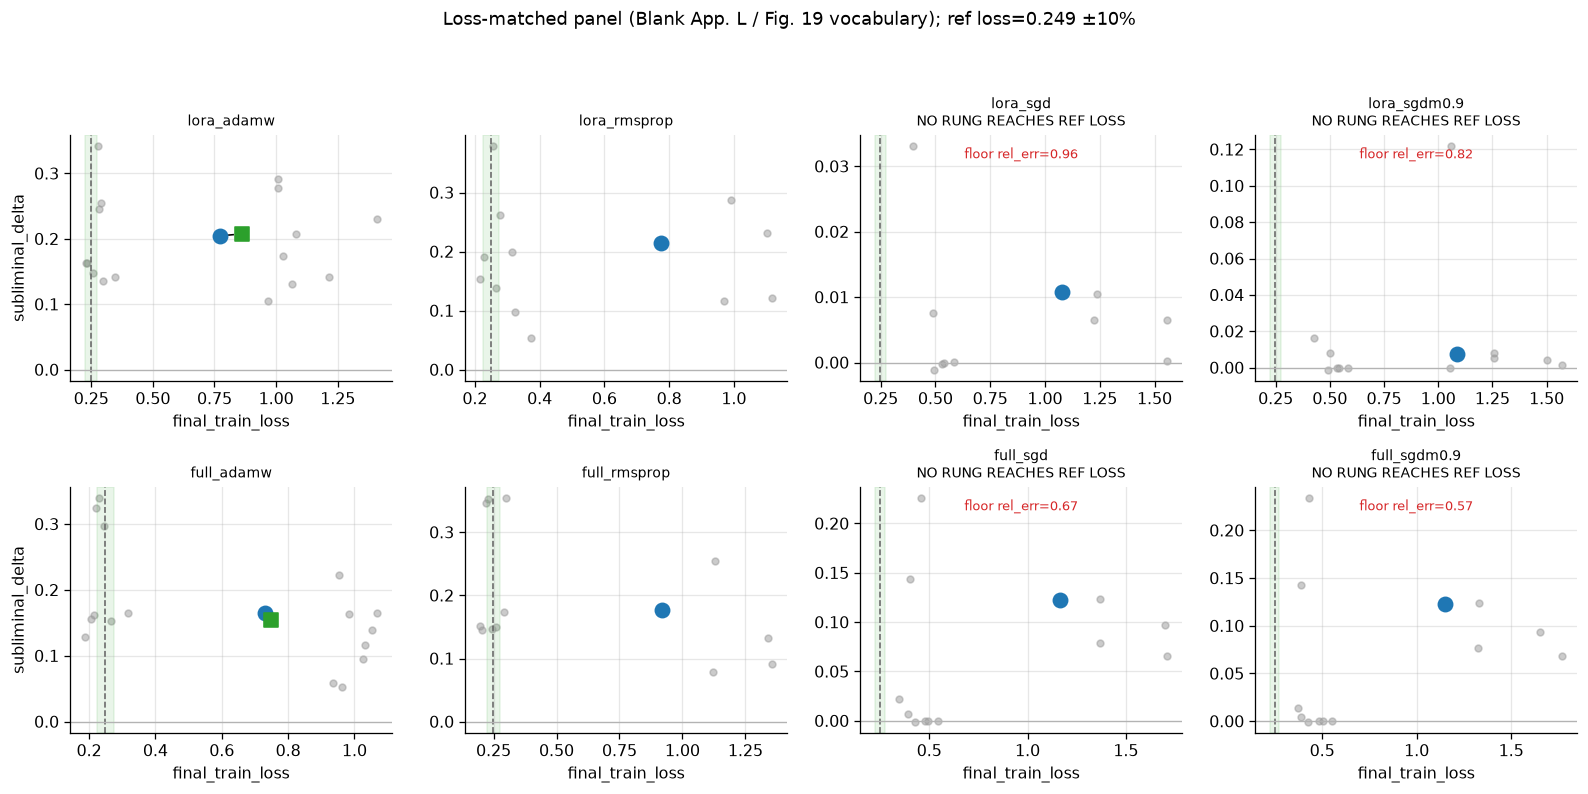

In [51]:
# Epoch-budget leaves only for loss-match panel
lm_e = loss_match[loss_match["max_steps"].isna()].copy()
print_opt_scope(lm_e, "epoch-budget leaves for loss panel")

# Per (arm, animal, init, lr): mean final_train_loss over (gseed, tfs) + delta from deduped
loss_by = (
    lm_e.groupby(["arm", "animal", "init", "student_lr"], dropna=False)
    .agg(
        final_train_loss=("final_train_loss", "mean"),
        loss_std=("final_train_loss", "std"),
        n_leaves=("final_train_loss", "count"),
        n_gseed=("gseed", "nunique"),
        n_tfs=("teacher_ftseed", "nunique"),
    )
    .reset_index()
)
# attach delta (test)
d_attach = delta[delta["set"] == PRIMARY][
    ["arm", "animal", "init", "student_lr", "subliminal_delta", "ci_lower", "ci_upper"]
]
loss_by = loss_by.merge(d_attach, on=["arm", "animal", "init", "student_lr"], how="left")

# Calibration meta
cal_meta = {a["arm"]: a for a in calib["arms"]}

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()
for i, arm in enumerate(ARM_ORDER):
    ax = axes[i]
    meta = cal_meta[arm]
    sub = loss_by[loss_by["arm"] == arm]
    # mean over inits×animals for display clarity, but keep points
    ax.scatter(
        sub["final_train_loss"],
        sub["subliminal_delta"],
        c="0.6",
        s=18,
        alpha=0.5,
        label="leaves (init×animal)",
    )
    # Selected LR centroid
    sel_lr = SELECTED_LRS[arm]
    sel = sub[np.isclose(sub["student_lr"], sel_lr)]
    if len(sel):
        ax.scatter(
            sel["final_train_loss"].mean(),
            sel["subliminal_delta"].mean(),
            c="C0", s=80, marker="o", zorder=4, label="selected LR",
        )
    lm_lr = meta["lr_lossmatch"]
    if lm_lr is not None and not math.isclose(float(lm_lr), float(sel_lr)):
        lms = sub[np.isclose(sub["student_lr"], float(lm_lr))]
        if len(lms):
            ax.scatter(
                lms["final_train_loss"].mean(),
                lms["subliminal_delta"].mean(),
                c="C2", s=80, marker="s", zorder=4, label="loss-match LR",
            )
            ax.plot(
                [sel["final_train_loss"].mean(), lms["final_train_loss"].mean()],
                [sel["subliminal_delta"].mean(), lms["subliminal_delta"].mean()],
                "k--", lw=1,
            )
    ax.axvline(ref_loss, color="0.4", ls="--", lw=1)
    ax.axvspan(band_lo, band_hi, color="C2", alpha=0.1)
    ax.axhline(0, color="0.7", lw=0.8)
    title = arm
    if meta["lossmatch_infeasible"]:
        title += "\nNO RUNG REACHES REF LOSS"
        ax.text(
            0.5, 0.95,
            f"floor rel_err={meta['lossmatch_rel_error']:.2f}",
            transform=ax.transAxes, ha="center", va="top", fontsize=8, color="C3",
        )
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("final_train_loss")
    if i % 4 == 0:
        ax.set_ylabel("subliminal_delta")
fig.suptitle(
    "Loss-matched panel (Blank App. L / Fig. 19 vocabulary); "
    f"ref loss={ref_loss:.3f} ±{tol:.0%}",
    fontsize=11,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## 7. Probe trajectories (Blank Fig. 2 style)

In-training `p_target` / `fc_share` / `ppl` for headline selected-LR treatments
vs the control band. Epoch-budget leaves only (`max_steps` NaN). Control band =
mean ± std across matched control leaves at the same `(arm, animal, step)`.


SCOPE: 9792 rows | 2 animals | 8 arms | 3 gseeds | 3 tfs | 12 lrs | epoch-budget probe rows
SCOPE: 6912 rows | 2 animals | 8 arms | 3 gseeds | 3 tfs | 5 lrs | headline selected-LR probes


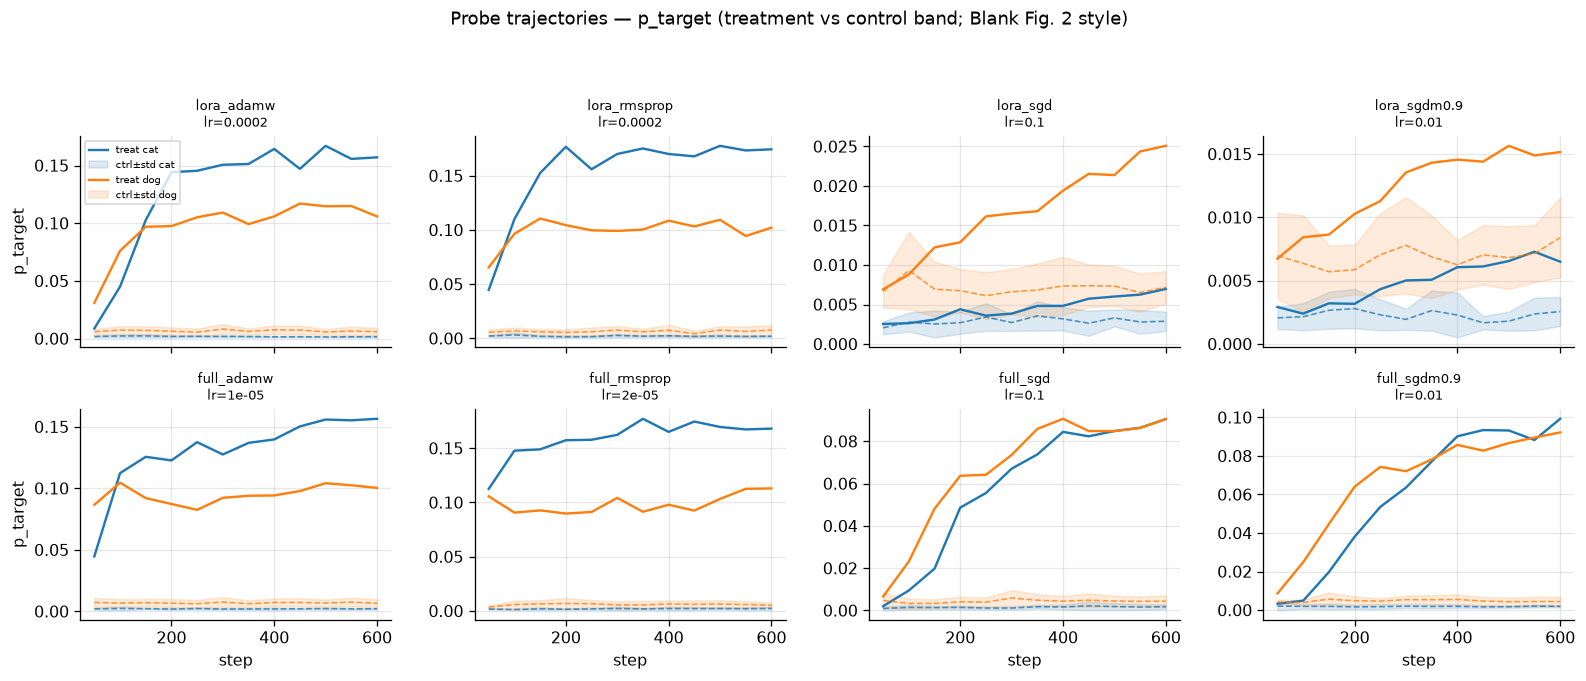

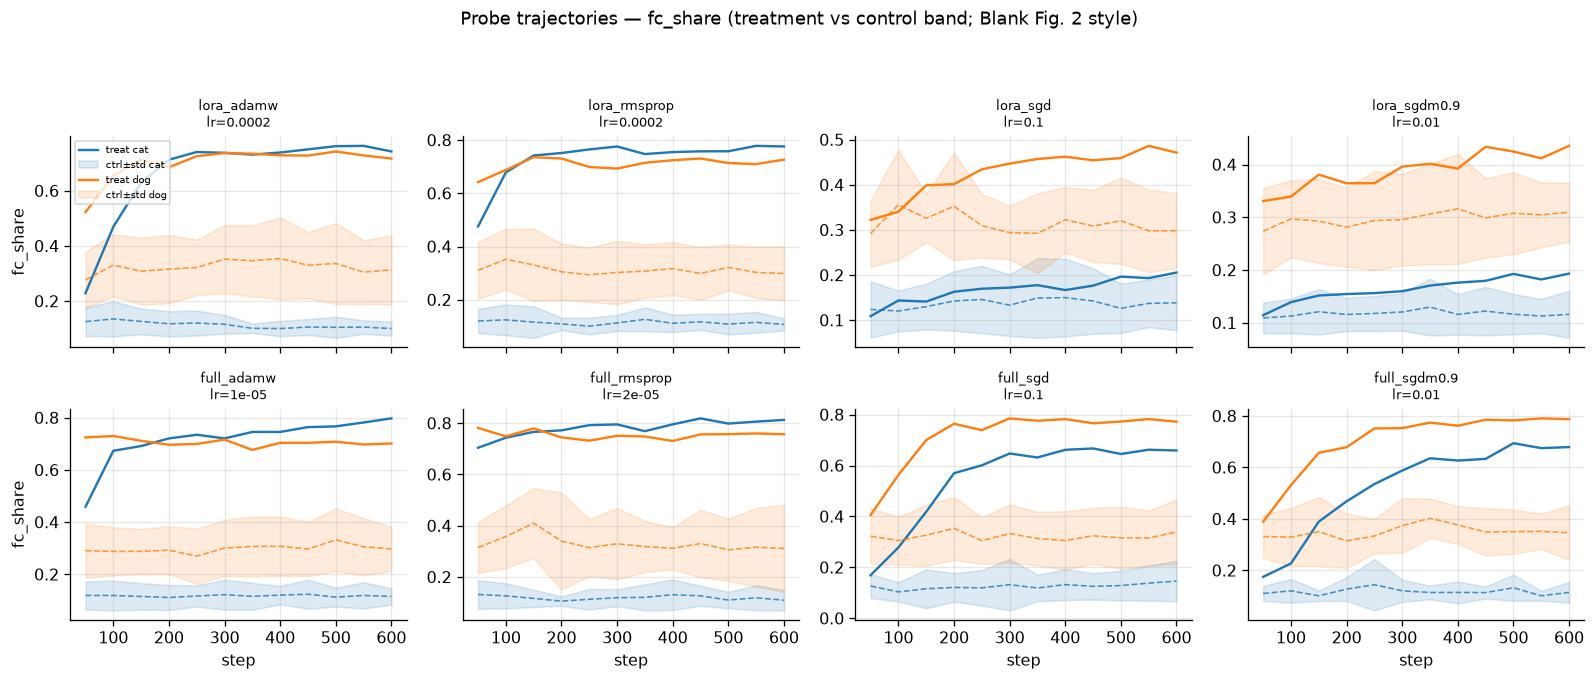

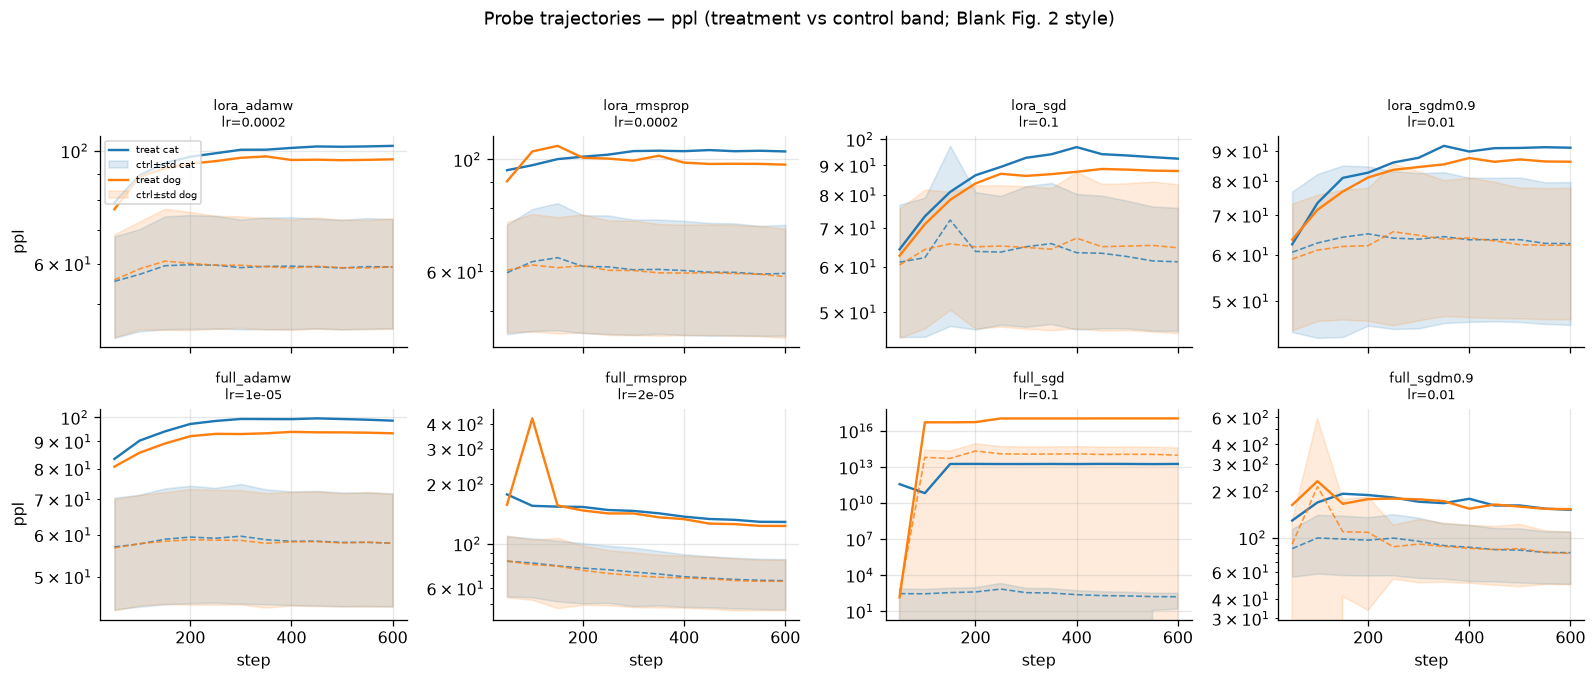

In [52]:
pr = probes.copy()
# Epoch budget: max_steps NaN; also drop superseded/phase0 step screens for this panel
pr_e = pr[pr["max_steps"].isna()].copy()
print_opt_scope(pr_e, "epoch-budget probe rows")

# Restrict to selected LRs
pr_h = pr_e[
    pr_e.apply(lambda r: is_selected_lr(r["arm"], r["student_lr"]), axis=1)
].copy()
print_opt_scope(pr_h, "headline selected-LR probes")

metrics = ["p_target", "fc_share", "ppl"]
# One figure per metric; 2×4 arms; treatment mean vs control band (pooled animals for space:
# facet by arm, lines by animal)
for metric in metrics:
    fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
    axes = axes.ravel()
    for i, arm in enumerate(ARM_ORDER):
        ax = axes[i]
        for animal, color in zip(plan.ANIMALS, ["C0", "C1"]):
            t = pr_h[
                (pr_h["arm"] == arm)
                & (pr_h["animal"] == animal)
                & (~pr_h["is_control"])
            ]
            c = pr_h[
                (pr_h["arm"] == arm)
                & (pr_h["animal"] == animal)
                & (pr_h["is_control"])
            ]
            if t.empty:
                continue
            tg = t.groupby("step")[metric].agg(["mean", "std", "count"]).sort_index()
            ax.plot(tg.index, tg["mean"], color=color, label=f"treat {animal}")
            if not c.empty:
                cg = c.groupby("step")[metric].agg(["mean", "std"]).sort_index()
                ax.fill_between(
                    cg.index,
                    cg["mean"] - cg["std"].fillna(0),
                    cg["mean"] + cg["std"].fillna(0),
                    color=color,
                    alpha=0.15,
                    label=f"ctrl±std {animal}",
                )
                ax.plot(cg.index, cg["mean"], color=color, ls="--", lw=1, alpha=0.8)
        if metric == "ppl":
            ax.set_yscale("log")
        ax.set_title(f"{arm}\nlr={SELECTED_LRS[arm]:g}", fontsize=8)
        if i % 4 == 0:
            ax.set_ylabel(metric)
        if i >= 4:
            ax.set_xlabel("step")
    axes[0].legend(fontsize=6, loc="best")
    fig.suptitle(
        f"Probe trajectories — {metric} (treatment vs control band; Blank Fig. 2 style)",
        fontsize=11,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


## 8. Seed / init robustness

### 8a. What the CSVs carry

| Object | Seed axes present | Notes |
|---|---|---|
| `optparam_delta` | **init** explicit; **gseed** collapsed into paired CI (`n_pairs`); **tfs** averaged inside `subliminal_delta_ci` | Primary claim grain |
| `optparam_loss_match` | **init, gseed, teacher_ftseed** | Per-leaf `final_train_loss`; δ column is the group-level join (constant within group) |
| `optparam_probe_trajectories` | **init(=model), gseed, teacher_ftseed** | Per-leaf dynamics |

We **never** silently average without printing scope. Paired CIs are
seed-matched (gseed); comparisons that pool unpaired cells are labelled.


SCOPE: 48 rows | 2 animals | 8 arms | 3 inits | 5 lrs | 1 sets | 2 tiers | headline per-init deltas (paired over gseed; tfs pre-averaged)


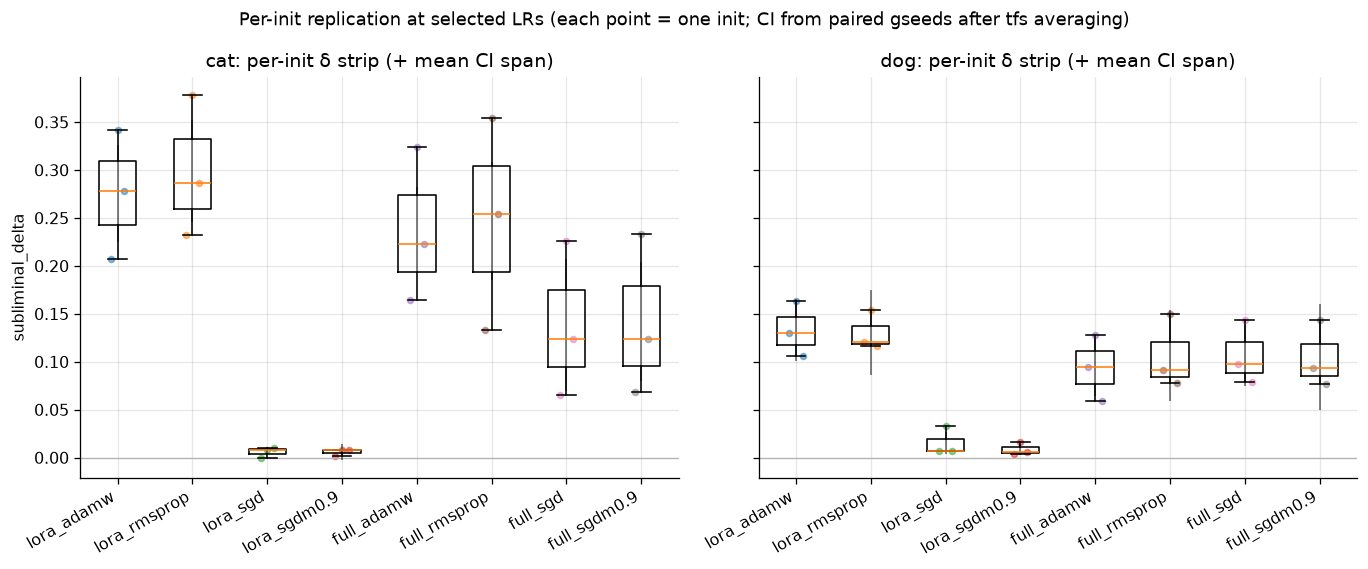

n_pairs at headline: n_pairs
3.0    48
Interpretation: n_pairs=3 ⇒ paired over student gseeds {0,1,2}. Teacher ftseeds are averaged inside each gseed before pairing (see gkd_results_io.subliminal_delta_ci).


In [53]:
head_d = delta[
    (delta["set"] == PRIMARY)
    & delta.apply(lambda r: is_selected_lr(r["arm"], r["student_lr"]), axis=1)
].copy()
head_d["init_label"] = head_d["init"].map(short_model)
print_opt_scope(head_d, "headline per-init deltas (paired over gseed; tfs pre-averaged)")

# Strip: distribution of per-init deltas by arm (pooled animals as separate hues via two panels)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, animal in zip(axes, plan.ANIMALS):
    sub = head_d[head_d["animal"] == animal]
    groups, labels = [], []
    for arm in ARM_ORDER:
        vals = sub[sub["arm"] == arm]["subliminal_delta"].to_numpy()
        groups.append(vals)
        labels.append(arm)
    aplots.strip_box(ax, groups, labels, zero_line=True, rotation=30)
    # overlay CI whiskers from mean of per-init CIs
    for i, arm in enumerate(ARM_ORDER):
        a = sub[sub["arm"] == arm]
        if a.empty:
            continue
        ax.vlines(
            i,
            a["ci_lower"].mean(),
            a["ci_upper"].mean(),
            colors="k",
            lw=1.2,
            alpha=0.5,
        )
    ax.set_title(f"{animal}: per-init δ strip (+ mean CI span)")
    ax.set_ylabel("subliminal_delta" if animal == "cat" else "")
fig.suptitle(
    "Per-init replication at selected LRs "
    "(each point = one init; CI from paired gseeds after tfs averaging)",
    fontsize=11,
)
fig.tight_layout()
plt.show()

# Show n_pairs / which seeds
print("n_pairs at headline:", head_d["n_pairs"].value_counts().to_string())
print(
    "Interpretation: n_pairs=3 ⇒ paired over student gseeds {0,1,2}. "
    "Teacher ftseeds are averaged inside each gseed before pairing "
    "(see gkd_results_io.subliminal_delta_ci)."
)


### 8b. Variance decomposition (descriptive)

Method: for headline selected-LR **epoch-budget** probe end-of-run `p_target`
(treatment only), compute the standard deviation of leaf values after grouping
out each axis in turn. Also report (i) across-init std of paired δ and
(ii) mean half-width of the paired gseed CI. This is a **descriptive
range/std breakdown**, not a formal random-effects ANOVA — do not overclaim.


In [54]:
# End-of-run probes at selected LR
eor = (
    pr_h[~pr_h["is_control"]]
    .sort_values("step")
    .groupby(
        ["arm", "animal", "model", "gseed", "teacher_ftseed", "run_dir"],
        dropna=False,
    )
    .tail(1)
    .copy()
)
print_opt_scope(eor, "end-of-run treatment probes at selected LR")

rows = []
for arm in ARM_ORDER:
    sub = eor[eor["arm"] == arm]
    if sub.empty:
        continue
    # overall
    rows.append({"arm": arm, "axis": "overall_leaf", "std": sub["p_target"].std(ddof=1), "n": len(sub)})
    for axis, col in [
        ("across_gseed", "gseed"),
        ("across_tfs", "teacher_ftseed"),
        ("across_init", "model"),
        ("across_animal", "animal"),
    ]:
        # mean of within-complement group stds? Better: std of axis-means
        means = sub.groupby(col)["p_target"].mean()
        rows.append({"arm": arm, "axis": axis, "std": means.std(ddof=1) if len(means) > 1 else 0.0, "n": len(means)})

var_probe = pd.DataFrame(rows)
print("Probe p_target end-of-run — std of axis-level means (descriptive):")
display(var_probe.pivot_table(index="arm", columns="axis", values="std"))

# Delta: across-init std + mean CI half-width (gseed uncertainty proxy)
drows = []
for arm in ARM_ORDER:
    for animal in plan.ANIMALS:
        sub = head_d[(head_d["arm"] == arm) & (head_d["animal"] == animal)]
        if sub.empty:
            continue
        drows.append(
            {
                "arm": arm,
                "animal": animal,
                "std_across_init": sub["subliminal_delta"].std(ddof=1),
                "range_across_init": sub["subliminal_delta"].max() - sub["subliminal_delta"].min(),
                "mean_ci_halfwidth": ((sub["ci_upper"] - sub["ci_lower"]) / 2).mean(),
                "n_inits": sub["init"].nunique(),
                "mean_n_pairs": sub["n_pairs"].mean(),
            }
        )
var_delta = pd.DataFrame(drows)
print("\nPaired δ — across-init dispersion vs within-init gseed CI half-width:")
display(var_delta)
print(
    "Limits: tfs is not a separate δ axis in the CSV (pre-averaged). "
    "CI half-width is the project paired-seed uncertainty, not an across-tfs std."
)

# Training-loss variance across gseed vs tfs (from loss_match)
lm_h = lm_e[
    lm_e.apply(lambda r: is_selected_lr(r["arm"], r["student_lr"]), axis=1)
].copy()
print_opt_scope(lm_h, "loss_match leaves at selected LR")
loss_var = []
for arm in ARM_ORDER:
    sub = lm_h[lm_h["arm"] == arm]
    if sub.empty:
        continue
    loss_var.append(
        {
            "arm": arm,
            "std_gseed_means": sub.groupby("gseed")["final_train_loss"].mean().std(ddof=1),
            "std_tfs_means": sub.groupby("teacher_ftseed")["final_train_loss"].mean().std(ddof=1),
            "std_init_means": sub.groupby("init")["final_train_loss"].mean().std(ddof=1),
            "n_leaves": len(sub),
        }
    )
display(pd.DataFrame(loss_var))


SCOPE: 432 rows | 2 animals | 8 arms | 3 gseeds | 3 tfs | 5 lrs | end-of-run treatment probes at selected LR
Probe p_target end-of-run — std of axis-level means (descriptive):


axis,across_animal,across_gseed,across_init,across_tfs,overall_leaf
arm,,,,,
full_adamw,0.039723,0.009497,0.052787,0.005264,0.065430
full_rmsprop,0.038988,0.012808,0.053146,0.011024,0.069798
full_sgd,0.000015,0.005733,0.039036,0.004449,0.047313
full_sgdm0.9,0.005003,0.007647,0.034682,0.008273,0.049007
lora_adamw,0.036217,0.001822,0.044963,0.011392,0.064643
lora_rmsprop,0.051116,0.007117,0.054045,0.013584,0.073040
lora_sgd,0.012807,0.001961,0.009732,0.000952,0.017361
lora_sgdm0.9,0.006124,0.000391,0.005685,0.003447,0.010559



Paired δ — across-init dispersion vs within-init gseed CI half-width:


,arm,animal,std_across_init,range_across_init,mean_ci_halfwidth,n_inits,mean_n_pairs
0,lora_adamw,cat,0.067217,0.134366,0.050537,3,3.0
1,lora_adamw,dog,0.029107,0.058002,0.032410,3,3.0
2,lora_rmsprop,cat,0.074022,0.146548,0.053359,3,3.0
3,lora_rmsprop,dog,0.020542,0.037512,0.044666,3,3.0
4,lora_sgd,cat,0.005282,0.010241,0.003553,3,3.0
5,lora_sgd,dog,0.015328,0.026574,0.011729,3,3.0
6,lora_sgdm0.9,cat,0.003886,0.006781,0.008362,3,3.0
7,lora_sgdm0.9,dog,0.006753,0.012371,0.005284,3,3.0
8,full_adamw,cat,0.080795,0.159743,0.044932,3,3.0
9,full_adamw,dog,0.034290,0.068563,0.029729,3,3.0


Limits: tfs is not a separate δ axis in the CSV (pre-averaged). CI half-width is the project paired-seed uncertainty, not an across-tfs std.
SCOPE: 432 rows | 2 animals | 8 arms | 3 inits | 3 gseeds | 3 tfs | 5 lrs | loss_match leaves at selected LR


,arm,std_gseed_means,std_tfs_means,std_init_means,n_leaves
0,lora_adamw,0.003799,0.003813,0.449388,54
1,lora_rmsprop,0.012676,0.004440,0.471881,54
2,lora_sgd,0.024743,0.013175,0.571971,54
3,lora_sgdm0.9,0.005363,0.005497,0.556671,54
4,full_adamw,0.002329,0.011830,0.459733,54
5,full_rmsprop,0.011844,0.025070,0.564329,54
6,full_sgd,0.059873,0.016777,0.660179,54
7,full_sgdm0.9,0.017807,0.048450,0.671000,54


### 8c. Missing-cell / quarantine imbalance audit

Unbalanced averaging is a risk when quarantined rungs or missing
(init × tfs × gseed) combos silently shrink an arm's denominator.


In [55]:
# Expected Phase-2 headline leaf grid from plan
exp_p2 = []
for arm in ARM_ORDER:
    lr = SELECTED_LRS[arm]
    for animal in plan.ANIMALS:
        for init in INIT_ORDER:
            for tfs in plan.TFS_HEADLINE:
                for gseed in plan.GSEEDS:
                    exp_p2.append(
                        {
                            "arm": arm,
                            "student_lr": lr,
                            "animal": animal,
                            "init": init,
                            "teacher_ftseed": tfs,
                            "gseed": gseed,
                        }
                    )
exp_p2 = pd.DataFrame(exp_p2)
# Actual from loss_match
got = lm_h.copy()
got_keys = set(
    zip(
        got["arm"],
        got["animal"],
        got["init"],
        got["teacher_ftseed"].fillna(-1).astype(int),
        got["gseed"].astype(int),
    )
)
exp_keys = set(
    zip(
        exp_p2["arm"],
        exp_p2["animal"],
        exp_p2["init"],
        exp_p2["teacher_ftseed"],
        exp_p2["gseed"],
    )
)
missing_leaves = sorted(exp_keys - got_keys)
extra = sorted(got_keys - exp_keys)
print(f"Expected Phase-2 headline treatment leaves: {len(exp_keys)}")
print(f"Present in loss_match at selected LR: {len(got_keys)}")
print(f"Missing: {len(missing_leaves)}  Extra (e.g. loss-match tier / other): check below")
if missing_leaves[:20]:
    print("First missing:", missing_leaves[:20])
# Loss-match tier cells (tfs=0 only) where lr_lossmatch != selected
print("\nLoss-match tier yamls from submit_p2:", campaign_state["transitions"]["submit_p2"].get("lossmatch_yamls"))
print("Quarantined rungs (no Phase-2 cells by design):", claims_doc.get("dropped_arms"), quarantine[quarantine.tier=='quarantine'][['arm','lr']].to_dict('records'))


Expected Phase-2 headline treatment leaves: 432
Present in loss_match at selected LR: 432
Missing: 0  Extra (e.g. loss-match tier / other): check below

Loss-match tier yamls from submit_p2: ['gkd_op_p2lm_full_adamw.yaml', 'gkd_op_p2lm_lora_adamw.yaml']
Quarantined rungs (no Phase-2 cells by design): [] [{'arm': 'lora_sgdm0.9', 'lr': 0.1}]


## 9. Capability guardrail — δ vs `perplexity_ratio`

A “success” that is really divergence must be visible. Points are per-init
headline rows (deduped). The main scatter keeps `perplexity_ratio` ≤ 10 so
the typical range is readable; collapsed cells (ratio > 10) are plotted
underneath on a log-x panel. Same arm colors on both.


SCOPE: 48 rows | 2 animals | 8 arms | 3 inits | 5 lrs | 1 sets | 2 tiers | capability guardrail scatter
perplexity_ratio split at 10: main=46 extreme=2 nonfinite=0


/tmp/ipykernel_343527/229095071.py:22: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


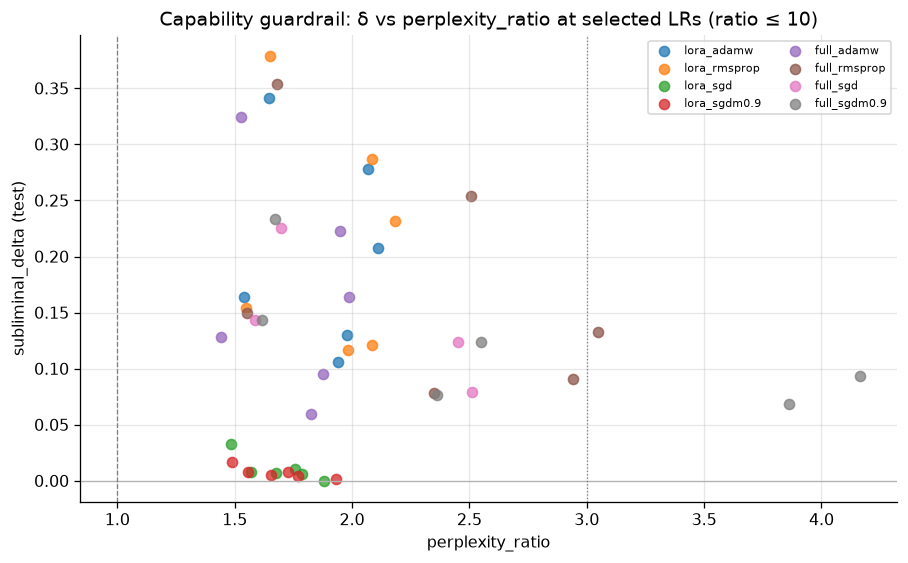

/tmp/ipykernel_343527/229095071.py:46: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


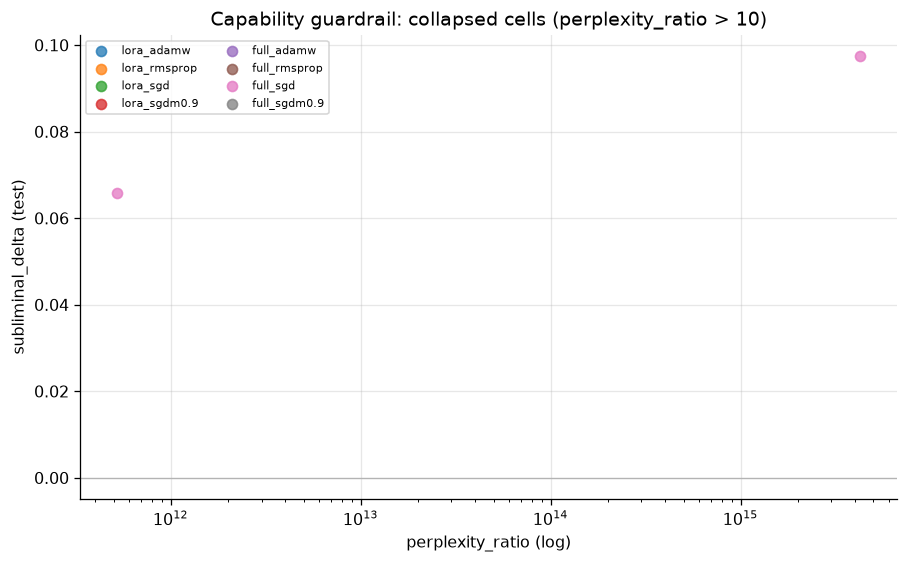

,arm,animal,init,subliminal_delta,perplexity_ratio,tier
172,full_sgd,cat,pythia-160m,0.065752,5.224073e+11,advisory
208,full_sgd,dog,pythia-160m,0.097445,4.240464e+15,advisory


Rows with perplexity_ratio>3 AND δ>0.05: 5


,arm,animal,init,subliminal_delta,perplexity_ratio,tier
100,full_rmsprop,cat,pythia-160m,0.133071,3.049655e+00,advisory
172,full_sgd,cat,pythia-160m,0.065752,5.224073e+11,advisory
208,full_sgd,dog,pythia-160m,0.097445,4.240464e+15,advisory
244,full_sgdm0.9,cat,pythia-160m,0.068224,3.860468e+00,advisory
280,full_sgdm0.9,dog,pythia-160m,0.093868,4.163587e+00,advisory


In [63]:
guard = head_d.copy()
print_opt_scope(guard, "capability guardrail scatter")

# Linear x is unreadable once a cell hits 1e11–1e15. Split at 10 so the
# majority (ratios ~1–4) stay on the main panel; collapsed cells go below.
PPL_RATIO_MAIN_MAX = 10.0
_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
ARM_COLORS = {arm: _cycle[i % len(_cycle)] for i, arm in enumerate(ARM_ORDER)}
_ratio = guard["perplexity_ratio"]
_finite = _ratio.notna() & np.isfinite(_ratio)
guard_main = guard.loc[_finite & (_ratio <= PPL_RATIO_MAIN_MAX)]
guard_extreme = guard.loc[_finite & (_ratio > PPL_RATIO_MAIN_MAX)]
print(
    f"perplexity_ratio split at {PPL_RATIO_MAIN_MAX:g}: "
    f"main={len(guard_main)} extreme={len(guard_extreme)} "
    f"nonfinite={int((~_finite).sum())}"
)

fig, ax = plt.subplots(figsize=(8, 5))
for arm in ARM_ORDER:
    sub = guard_main[guard_main["arm"] == arm]
    ax.scatter(
        sub["perplexity_ratio"],
        sub["subliminal_delta"],
        label=arm,
        s=40,
        alpha=0.75,
        c=ARM_COLORS[arm],
    )
ax.axhline(0, color="0.7", lw=0.8)
ax.axvline(1.0, color="0.5", ls="--", lw=0.8)
ax.axvline(3.0, color="0.5", ls=":", lw=0.8)
ax.set_xlabel("perplexity_ratio")
ax.set_ylabel("subliminal_delta (test)")
ax.legend(fontsize=7, ncol=2)
ax.set_title(
    "Capability guardrail: δ vs perplexity_ratio at selected LRs "
    f"(ratio ≤ {PPL_RATIO_MAIN_MAX:g})"
)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for arm in ARM_ORDER:
    sub = guard_extreme[guard_extreme["arm"] == arm]
    ax.scatter(
        sub["perplexity_ratio"],
        sub["subliminal_delta"],
        label=arm,
        s=40,
        alpha=0.75,
        c=ARM_COLORS[arm],
    )
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("perplexity_ratio (log)")
ax.set_ylabel("subliminal_delta (test)")
ax.legend(fontsize=7, ncol=2)
ax.set_title(
    "Capability guardrail: collapsed cells "
    f"(perplexity_ratio > {PPL_RATIO_MAIN_MAX:g})"
)
fig.tight_layout()
plt.show()
if len(guard_extreme):
    display(
        guard_extreme[
            ["arm", "animal", "init", "subliminal_delta", "perplexity_ratio", "tier"]
        ].sort_values("perplexity_ratio")
    )

# Flag high-ppl "successes"
hi = guard[(guard["perplexity_ratio"] > 3.0) & (guard["subliminal_delta"] > 0.05)]
print(f"Rows with perplexity_ratio>3 AND δ>0.05: {len(hi)}")
if len(hi):
    display(hi[["arm", "animal", "init", "subliminal_delta", "perplexity_ratio", "tier"]])
else:
    print("  (none at selected LRs after dedupe)")


### 9b. lm-eval vs own-init base

**What this measures.** 0-shot PolyPythia tasks (`lambada_openai`, `arc_easy`,
`sciq`) already on `sdf_capability_summary.json` at **selected LRs only**.
Loader: `load_gkd_capability_results`. Each JSON pre-averages student gseeds
and stores the paired untrained Pythia for **that init** (`base_*`; `delta_*`
= student − that base). Own-base bars use those paired values — not one
original-seed number for all three inits.

Benches were not written for loss-match / extra-LR cells (Pile PPL only; see
the SCOPE print). LAMBADA harness perplexity is not plotted (collapsed SGD
cells explode). Dashed line on ARC-Easy / SciQ is 4-option chance (0.25).


SCOPE: 144 rows | 2 animals | 8 arms | 3 tfs | 5 lrs | lm-eval treatment (gseeds pre-averaged in JSON)
SCOPE: 48 rows | 2 animals | 8 arms | 0 tfs | 5 lrs | lm-eval control
ppl_n_seeds: [3] | capability rows without lm-eval (PPL-only, excluded): 108
SCOPE: 48 rows | 2 animals | 8 arms | treatment after averaging teacher ftseeds


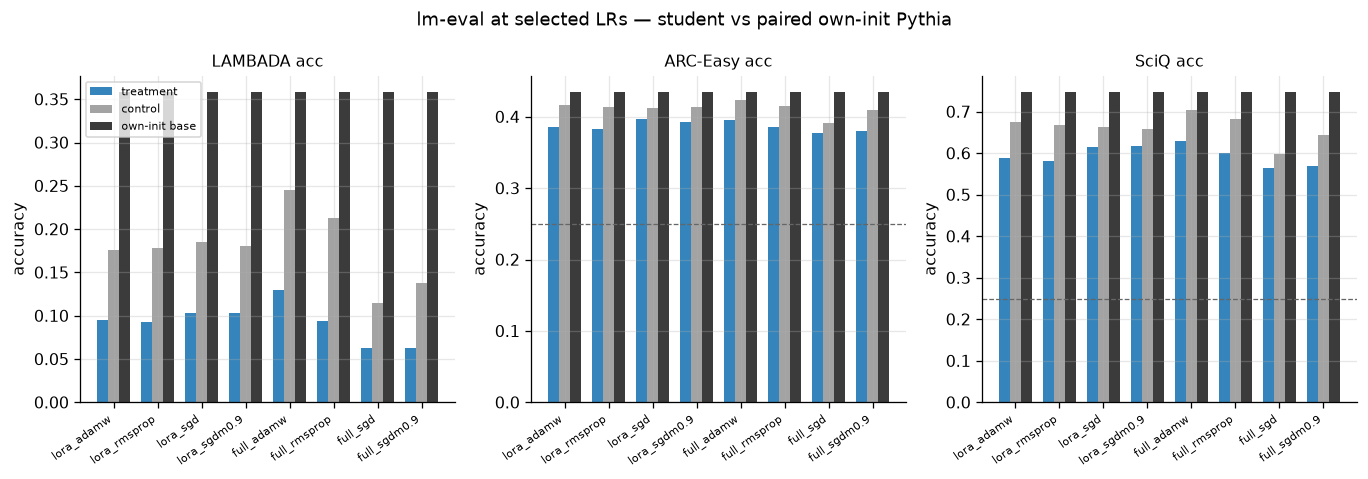

Per-arm mean accuracy (treat/ctrl over animal×init; base = paired treat base_*):


,arm,treat_LAMBADA,ctrl_LAMBADA,base_LAMBADA,treat_ARC-Easy,ctrl_ARC-Easy,base_ARC-Easy,treat_SciQ,ctrl_SciQ,base_SciQ
0,lora_adamw,0.096,0.176,0.359,0.385,0.416,0.435,0.589,0.675,0.748
1,lora_rmsprop,0.093,0.179,0.359,0.383,0.414,0.435,0.582,0.668,0.748
2,lora_sgd,0.103,0.185,0.359,0.396,0.413,0.435,0.616,0.664,0.748
3,lora_sgdm0.9,0.103,0.181,0.359,0.392,0.413,0.435,0.616,0.659,0.748
4,full_adamw,0.130,0.245,0.359,0.396,0.424,0.435,0.630,0.703,0.748
5,full_rmsprop,0.094,0.213,0.359,0.386,0.415,0.435,0.599,0.683,0.748
6,full_sgd,0.063,0.115,0.359,0.377,0.391,0.435,0.564,0.597,0.748
7,full_sgdm0.9,0.063,0.138,0.359,0.380,0.409,0.435,0.569,0.643,0.748


SCOPE: 48 rows | 2 animals | 8 arms | 3 inits | 5 lrs | 1 sets | 2 tiers | headline δ ⋈ tfs-averaged lm-eval


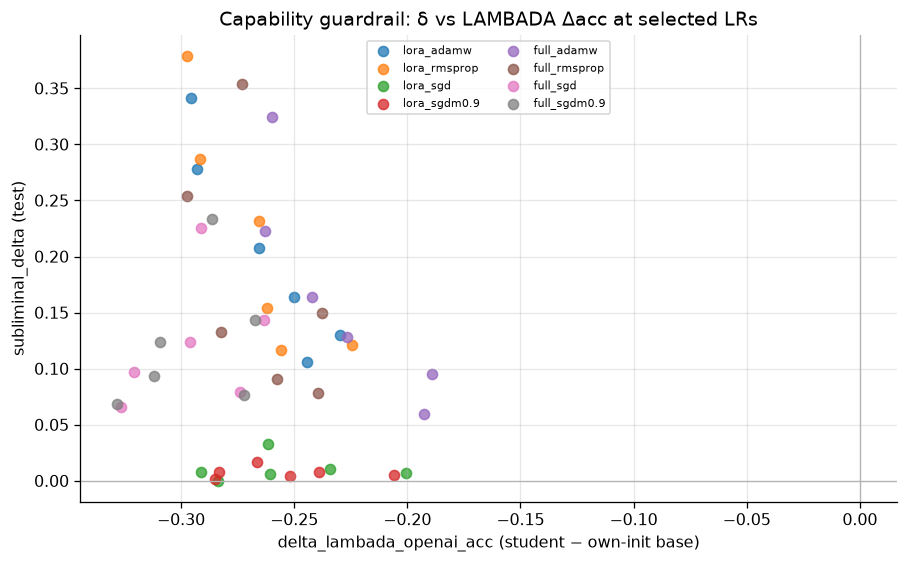

In [57]:
from subliminal_learning.evaluation.gkd_results_io import load_gkd_capability_results

cap_lm = load_gkd_capability_results(OUTPUT_ROOT, SUBDIR)
if cap_lm.empty:
    raise RuntimeError(f"no sdf_capability_summary.json under {TREE}")
if "bench_lambada_openai_acc" not in cap_lm.columns:
    raise RuntimeError("capability summaries have no lm-eval columns")


def _cap_arm(row) -> str:
    kind = "full" if row["student_mode"] == "full" else "lora"
    slug = optim_slug(str(row["student_optim"]), float(row["optim_momentum"] or 0.0))
    return f"{kind}_{slug}"


cap_lm = cap_lm.copy()
cap_lm["arm"] = cap_lm.apply(_cap_arm, axis=1)
bench = cap_lm.loc[cap_lm["bench_lambada_openai_acc"].notna()].copy()
if bench.empty:
    raise RuntimeError("no lm-eval rows on disk (expected selected-LR summaries)")

off_ladder = bench.loc[
    ~bench.apply(lambda r: is_selected_lr(r["arm"], r["student_lr"]), axis=1)
]
if not off_ladder.empty:
    raise RuntimeError(f"lm-eval rows at non-selected LRs: {len(off_ladder)}")

print_opt_scope(bench.loc[~bench["is_control"]], "lm-eval treatment (gseeds pre-averaged in JSON)")
print_opt_scope(bench.loc[bench["is_control"]], "lm-eval control")
print(
    "ppl_n_seeds:",
    sorted(bench["ppl_n_seeds"].dropna().unique().tolist()),
    "| capability rows without lm-eval (PPL-only, excluded):",
    int(cap_lm["bench_lambada_openai_acc"].isna().sum()),
)

_metric_cols = [
    c
    for c in bench.columns
    if c.startswith(("bench_", "base_", "delta_")) or c == "perplexity_ratio"
]
_keys = ["animal", "model", "arm"]
treat_lm = (
    bench.loc[~bench["is_control"]]
    .groupby(_keys, dropna=False)[_metric_cols]
    .mean()
    .reset_index()
)
ctrl_lm = bench.loc[bench["is_control"]].copy()
print_opt_scope(treat_lm, "treatment after averaging teacher ftseeds")

ACC = [
    ("bench_lambada_openai_acc", "base_lambada_openai_acc", "LAMBADA acc"),
    ("bench_arc_easy_acc", "base_arc_easy_acc", "ARC-Easy acc"),
    ("bench_sciq_acc", "base_sciq_acc", "SciQ acc"),
]

x = np.arange(len(ARM_ORDER))
width = 0.25
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=False)
for ax, (bcol, basecol, title) in zip(axes, ACC):
    treat_y = treat_lm.groupby("arm")[bcol].mean().reindex(ARM_ORDER)
    ctrl_y = ctrl_lm.groupby("arm")[bcol].mean().reindex(ARM_ORDER)
    base_y = treat_lm.groupby("arm")[basecol].mean().reindex(ARM_ORDER)
    ax.bar(x - width, treat_y.to_numpy(), width, label="treatment", color="C0", alpha=0.9)
    ax.bar(x, ctrl_y.to_numpy(), width, label="control", color="0.6", alpha=0.9)
    ax.bar(x + width, base_y.to_numpy(), width, label="own-init base", color="0.15", alpha=0.9)
    if title.startswith("ARC") or title.startswith("SciQ"):
        ax.axhline(0.25, color="0.4", ls="--", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(ARM_ORDER, rotation=35, ha="right", fontsize=7)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("accuracy")
axes[0].legend(fontsize=7)
fig.suptitle("lm-eval at selected LRs — student vs paired own-init Pythia", fontsize=11)
fig.tight_layout()
plt.show()

tab_rows = []
for arm in ARM_ORDER:
    t = treat_lm.loc[treat_lm["arm"] == arm]
    c = ctrl_lm.loc[ctrl_lm["arm"] == arm]
    row = {"arm": arm}
    for bcol, basecol, title in ACC:
        short = title.split()[0]
        row[f"treat_{short}"] = float(t[bcol].mean())
        row[f"ctrl_{short}"] = float(c[bcol].mean())
        row[f"base_{short}"] = float(t[basecol].mean())
    tab_rows.append(row)
tab_lm = pd.DataFrame(tab_rows)
print("Per-arm mean accuracy (treat/ctrl over animal×init; base = paired treat base_*):")
display(tab_lm.style.format({col: "{:.3f}" for col in tab_lm.columns if col != "arm"}))

joined_lm = head_d.merge(
    treat_lm.rename(columns={"model": "init"}),
    on=["animal", "init", "arm"],
    how="inner",
    suffixes=("", "_cap"),
)
if len(joined_lm) != len(head_d):
    raise RuntimeError(
        f"lm-eval join to head_d incomplete: {len(joined_lm)} vs {len(head_d)}"
    )
print_opt_scope(joined_lm, "headline δ ⋈ tfs-averaged lm-eval")

fig, ax = plt.subplots(figsize=(8, 5))
for arm in ARM_ORDER:
    sub = joined_lm.loc[joined_lm["arm"] == arm]
    ax.scatter(
        sub["delta_lambada_openai_acc"],
        sub["subliminal_delta"],
        label=arm,
        s=40,
        alpha=0.75,
    )
ax.axhline(0, color="0.7", lw=0.8)
ax.axvline(0, color="0.7", lw=0.8)
ax.set_xlabel("delta_lambada_openai_acc (student − own-init base)")
ax.set_ylabel("subliminal_delta (test)")
ax.legend(fontsize=7, ncol=2)
ax.set_title("Capability guardrail: δ vs LAMBADA Δacc at selected LRs")
fig.tight_layout()
plt.show()


## 10. Specificity — FC `target_share` vs probe `fc_share`

The persisted delta CSVs do **not** include preference/FC `target_share`
columns. Specificity is available in-training as probe `fc_share`. We report
end-of-run `fc_share` at selected LRs (treatment vs control).


CSV columns containing 'share' or 'fc': []
probe columns: ['fc_share', 'fc_argmax_frac']
SCOPE: 432 rows | 2 animals | 8 arms | 3 gseeds | 3 tfs | 5 lrs | end-of-run fc_share (treatment, selected LR)


,arm,animal,fc_share_mean,fc_share_std,p_target_mean,n
0,full_adamw,cat,0.797491,0.098690,0.156499,27
1,full_adamw,dog,0.701351,0.091093,0.100322,27
2,full_rmsprop,cat,0.812800,0.097706,0.168095,27
3,full_rmsprop,dog,0.756981,0.078293,0.112957,27
4,full_sgd,cat,0.659168,0.160850,0.090490,27
5,full_sgd,dog,0.772039,0.161515,0.090512,27
6,full_sgdm0.9,cat,0.679025,0.148388,0.099284,27
7,full_sgdm0.9,dog,0.787387,0.090278,0.092208,27
8,lora_adamw,cat,0.742585,0.124940,0.157095,27
9,lora_adamw,dog,0.716763,0.081210,0.105876,27


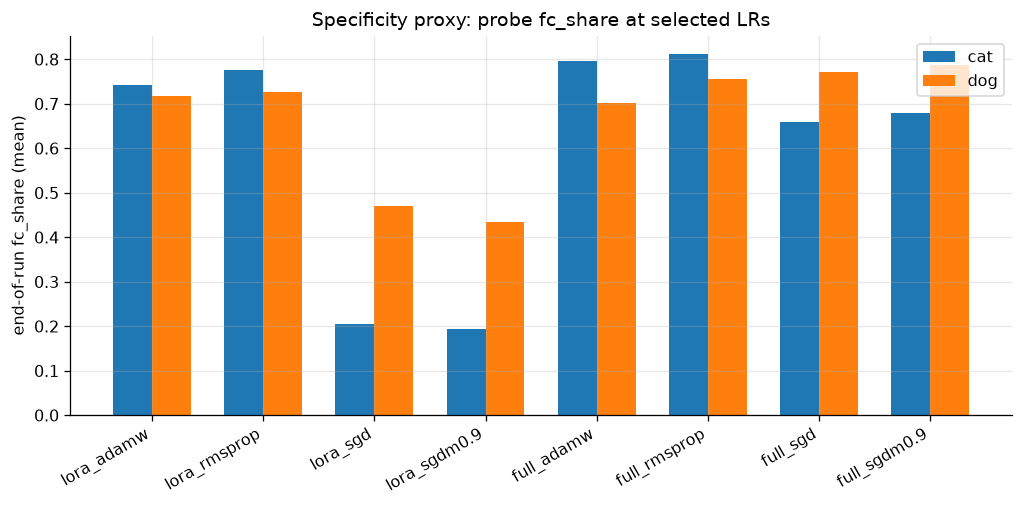

GAP: eval-grade FC target_share is not in results/*.csv; re-deriving it from leaf JSON would violate the prereg finalize contract.


In [58]:
print(
    "CSV columns containing 'share' or 'fc':",
    [c for c in list(delta.columns) + list(delta_agg.columns) if "share" in c or c.startswith("fc")],
)
print("probe columns:", [c for c in probes.columns if "fc" in c or "share" in c])

eor_fc = eor.copy()
fc_summary = (
    eor_fc.groupby(["arm", "animal"])
    .agg(
        fc_share_mean=("fc_share", "mean"),
        fc_share_std=("fc_share", "std"),
        p_target_mean=("p_target", "mean"),
        n=("fc_share", "count"),
    )
    .reset_index()
)
print_opt_scope(eor_fc, "end-of-run fc_share (treatment, selected LR)")
display(fc_summary.sort_values(["arm", "animal"]))

fig, ax = plt.subplots(figsize=(9, 4.5))
arms_x = np.arange(len(ARM_ORDER))
w = 0.35
for j, animal in enumerate(plan.ANIMALS):
    vals = [
        fc_summary[
            (fc_summary["arm"] == a) & (fc_summary["animal"] == animal)
        ]["fc_share_mean"].mean()
        for a in ARM_ORDER
    ]
    ax.bar(arms_x + (j - 0.5) * w, vals, width=w, label=animal)
ax.set_xticks(arms_x)
ax.set_xticklabels(ARM_ORDER, rotation=30, ha="right")
ax.set_ylabel("end-of-run fc_share (mean)")
ax.set_title("Specificity proxy: probe fc_share at selected LRs")
ax.legend()
fig.tight_layout()
plt.show()
print(
    "GAP: eval-grade FC target_share is not in results/*.csv; "
    "re-deriving it from leaf JSON would violate the prereg finalize contract."
)


## 11. Grad concentration (Phase-0 mechanism probe only)

Top-decile `|grad|` share from `optparam_grad_concentration.csv`. **Filter to
`max_steps == PHASE0_MAX_STEPS` (625)** so the superseded 200-step screen is not
mixed in. Correlational only — Phase-0 has no preference δ for most rungs.


grad rows: total=294 s625=147 s200=147 (s200 ignored below)
SCOPE: 147 rows | 1 animals | 8 arms | 1 gseeds | 1 tfs | 19 lrs | Phase-0 625-step grad concentration


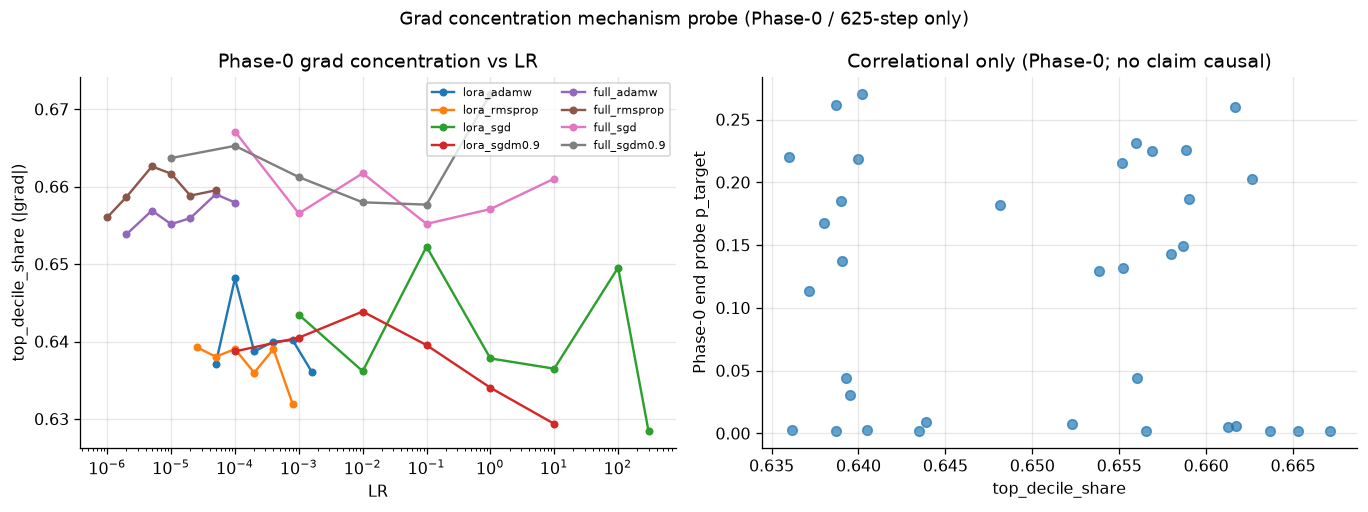

,arm,student_lr,top_decile_share,mean_abs_grad,n,final_train_loss,excluded,p_target
0,full_adamw,0.000002,0.653859,0.000022,3,0.320482,False,1.297094e-01
1,full_adamw,0.000005,0.656911,0.000021,3,0.250857,False,2.252436e-01
2,full_adamw,0.000010,0.655160,0.000022,3,0.217873,False,2.156195e-01
3,full_adamw,0.000020,0.655941,0.000021,3,0.229710,False,2.313524e-01
4,full_adamw,0.000050,0.659026,0.000022,3,0.436222,False,1.871184e-01
5,full_adamw,0.000100,0.657952,0.000022,3,1.204814,True,1.541614e-01
6,full_rmsprop,0.000001,0.656045,0.000022,3,0.351924,False,4.377409e-02
7,full_rmsprop,0.000002,0.658677,0.000021,3,0.283505,False,1.495343e-01
8,full_rmsprop,0.000005,0.662614,0.000020,3,0.227446,False,2.023344e-01
9,full_rmsprop,0.000010,0.661683,0.000021,3,0.210407,False,2.597830e-01


In [59]:
g625 = grads[grads["max_steps"] == plan.PHASE0_MAX_STEPS].copy()
g200 = grads[grads["max_steps"] == 200].copy()
print(f"grad rows: total={len(grads)} s625={len(g625)} s200={len(g200)} (s200 ignored below)")
print_opt_scope(g625, "Phase-0 625-step grad concentration")

# Average over early steps per (arm, lr)
g_arm = (
    g625.groupby(["arm", "student_lr"], dropna=False)
    .agg(
        top_decile_share=("top_decile_share", "mean"),
        mean_abs_grad=("mean_abs_grad", "mean"),
        n=("top_decile_share", "count"),
    )
    .reset_index()
)

# Join Phase-0 final loss / exclusion from calib
g_arm = g_arm.merge(
    p0[["arm", "lr", "final_train_loss", "excluded", "p_target"]].rename(
        columns={"lr": "student_lr"}
    ),
    on=["arm", "student_lr"],
    how="left",
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for arm in ARM_ORDER:
    sub = g_arm[g_arm["arm"] == arm].sort_values("student_lr")
    ax.plot(sub["student_lr"], sub["top_decile_share"], "o-", label=arm, ms=4)
ax.set_xscale("log")
ax.set_xlabel("LR")
ax.set_ylabel("top_decile_share (|grad|)")
ax.set_title("Phase-0 grad concentration vs LR")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
ok = g_arm[~g_arm["excluded"].fillna(False)]
ax.scatter(ok["top_decile_share"], ok["p_target"], c="C0", alpha=0.7)
ax.set_xlabel("top_decile_share")
ax.set_ylabel("Phase-0 end probe p_target")
ax.set_title("Correlational only (Phase-0; no claim causal)")
fig.suptitle(
    "Grad concentration mechanism probe (Phase-0 / 625-step only)",
    fontsize=11,
)
fig.tight_layout()
plt.show()
display(g_arm.sort_values(["arm", "student_lr"]).head(20))


## 12. Claims C1–C5 — verdicts with recomputed support

Thresholds from `optparam_plan` / `claims.json`. Support numbers are recomputed
from the **deduped** delta tables so they are not inflated by capability-join
duplicates. On-disk `claims.json` verdicts are shown alongside.


claims.json meta: {'prompt_set': 'test', 'scoring': 'prob', 'min_inits': 2, 'dropped_arms': []}
plan.CLAIM_MIN_INITS = 2
plan.SGD_NULL_EQUIVALENCE_FRACTION = 0.05

=== C1 Full FT present ===
statement: Full fine-tuning induces subliminal learning: full/adamw clears its matched control on >= 2 of 3 inits, both animals
claims.json verdict: supported
recomputed: replicates= True n_inits_positive= {'cat': 3, 'dog': 3} best_delta= 0.23711121278196245
verdict (recomputed): supported

=== C2 LR dependence ===
statement: The full/adamw effect depends on the learning rate: its spread across the Phase-1 ladder exceeds the within-rung seed CI width
claims.json: supported ladder_spread= 0.24521899958723226 mean_ci_width= 0.07466116976936742
recomputed: ladder_spread=0.211380 mean_ci_width=0.074661 n_rungs=4 → supported

=== C3 Adaptive optimizers ===
statement: Adaptive optimizers work under both parameterizations: every adamw / rmsprop arm clears its matched control
claims.json verdict: supported

,arm,selected_lr,recomputed_verdict,disk_verdict,best_delta,ci_upper_min,equivalence_bound,reference_adamw_delta,n_inits_positive,disk_quarantined_rungs,ladder_usable_range,lossmatch_infeasible
0,lora_sgd,0.10,effect_present,effect_present,0.015371,0.020099,0.013782,0.275644,"{'cat': 3, 'dog': 2}",[],"[0.001, 0.1]",True
1,lora_sgdm0.9,0.01,inconclusive,effect_present,0.008649,0.020549,0.013782,0.275644,"{'cat': 1, 'dog': 2}",[0.1],"[0.0001, 0.1]",True
2,full_sgd,0.10,effect_present,effect_present,0.138290,0.172801,0.011856,0.237111,"{'cat': 3, 'dog': 3}",[],"[0.0001, 0.1]",True
3,full_sgdm0.9,0.01,effect_present,effect_present,0.142017,0.171031,0.011856,0.237111,"{'cat': 3, 'dog': 3}",[],"[1e-05, 0.01]",True



=== C5 Interaction ===
statement: Interaction (novel): the optimizer's effect on the subliminal delta, measured relative to AdamW, differs between LoRA and full fine-tuning
claims.json verdict: measured contrasts= {'rmsprop': 0.01359773773453149, 'sgd': -0.16145150071385173, 'sgdm0.9': -0.17190043602437272}
recomputed contrasts: {'rmsprop': 0.0135977377345316, 'sgd': -0.16145150071385164, 'sgdm0.9': -0.1719004360243727}
max_abs_contrast: 0.1719004360243727


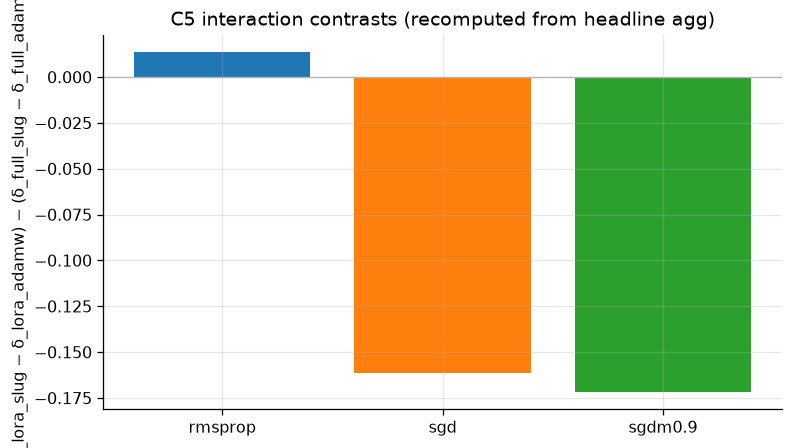

In [60]:
print("claims.json meta:",
      {k: claims_doc[k] for k in ("prompt_set", "scoring", "min_inits", "dropped_arms")})
print("plan.CLAIM_MIN_INITS =", plan.CLAIM_MIN_INITS)
print("plan.SGD_NULL_EQUIVALENCE_FRACTION =", plan.SGD_NULL_EQUIVALENCE_FRACTION)


def _arm_rows(agg: pd.DataFrame, arm: str) -> pd.DataFrame:
    rows = agg[(agg["arm"] == arm) & (agg["set"] == PRIMARY)]
    lr = SELECTED_LRS[arm]
    return rows[rows["student_lr"].apply(lambda x: math.isclose(float(x), lr))]


def _replicates(arm: str) -> tuple[bool, dict[str, int]]:
    rows = _arm_rows(delta_agg, arm)
    per = {
        animal: int(rows[rows["animal"] == animal]["n_inits_positive"].max())
        if len(rows[rows["animal"] == animal])
        else 0
        for animal in plan.ANIMALS
    }
    ok = all(v >= plan.CLAIM_MIN_INITS for v in per.values())
    return ok, per


# ----- C1 -----
c1 = next(c for c in claims_doc["claims"] if c["id"] == "C1")
ok1, per1 = _replicates("full_adamw")
rows1 = _arm_rows(delta_agg, "full_adamw")
best1 = float(rows1["subliminal_delta"].max()) if len(rows1) else float("nan")
print("\n=== C1 Full FT present ===")
print("statement:", c1["statement"])
print("claims.json verdict:", c1["verdict"])
print("recomputed: replicates=", ok1, "n_inits_positive=", per1, "best_delta=", best1)
print("verdict (recomputed):", "supported" if ok1 else "not_supported")

# ----- C2 -----
c2 = next(c for c in claims_doc["claims"] if c["id"] == "C2")
# ladder spread on full_adamw Phase-1 screen-init deltas
fa_ladder = delta[
    (delta["set"] == PRIMARY)
    & (delta["arm"] == "full_adamw")
    & (delta["init"] == screen_init_model)
]
ladder_spread = float(fa_ladder["subliminal_delta"].max() - fa_ladder["subliminal_delta"].min())
mean_ci_width = float(_arm_rows(delta_agg, "full_adamw")["mean_ci_width"].mean())
c2_ok = np.isfinite(ladder_spread) and np.isfinite(mean_ci_width) and ladder_spread > mean_ci_width
print("\n=== C2 LR dependence ===")
print("statement:", c2["statement"])
print("claims.json:", c2["verdict"], "ladder_spread=", c2.get("ladder_spread"), "mean_ci_width=", c2.get("mean_ci_width"))
print(
    f"recomputed: ladder_spread={ladder_spread:.6f} mean_ci_width={mean_ci_width:.6f} "
    f"n_rungs={fa_ladder['student_lr'].nunique()} → "
    f"{'supported' if c2_ok else 'not_supported'}"
)

# ----- C3 -----
c3 = next(c for c in claims_doc["claims"] if c["id"] == "C3")
adaptive = ["lora_adamw", "lora_rmsprop", "full_adamw", "full_rmsprop"]
c3_detail = {a: _replicates(a) for a in adaptive}
c3_ok = all(v[0] for v in c3_detail.values())
print("\n=== C3 Adaptive optimizers ===")
print("statement:", c3["statement"])
print("claims.json verdict:", c3["verdict"])
for a, (ok, per) in c3_detail.items():
    print(f"  {a}: replicates={ok} n_inits_positive={per} best_delta={_arm_rows(delta_agg, a)['subliminal_delta'].max():.4f}")
print("verdict (recomputed):", "supported" if c3_ok else "not_supported")

# ----- C4 -----
c4 = next(c for c in claims_doc["claims"] if c["id"] == "C4")
print("\n=== C4 SGD null (equivalence bound) ===")
print("statement:", c4["statement"])
sgd_arms = ["lora_sgd", "lora_sgdm0.9", "full_sgd", "full_sgdm0.9"]
adamw_of = {
    "lora_sgd": "lora_adamw",
    "lora_sgdm0.9": "lora_adamw",
    "full_sgd": "full_adamw",
    "full_sgdm0.9": "full_adamw",
}
c4_rows = []
for arm in sgd_arms:
    ok, per = _replicates(arm)
    rows = _arm_rows(delta_agg, arm)
    ci_upper_min = float(rows["ci_upper_max"].min()) if len(rows) else float("nan")
    ref_arm = adamw_of[arm]
    ref_delta = float(_arm_rows(delta_agg, ref_arm)["subliminal_delta"].max())
    bound = plan.SGD_NULL_EQUIVALENCE_FRACTION * ref_delta
    if ok:
        verdict = "effect_present"
    elif ci_upper_min < bound:
        verdict = "null_bounded"
    else:
        verdict = "inconclusive"
    disk = c4["arms"][arm]
    c4_rows.append(
        {
            "arm": arm,
            "selected_lr": SELECTED_LRS[arm],
            "recomputed_verdict": verdict,
            "disk_verdict": disk["verdict"],
            "best_delta": float(rows["subliminal_delta"].max()) if len(rows) else float("nan"),
            "ci_upper_min": ci_upper_min,
            "equivalence_bound": bound,
            "reference_adamw_delta": ref_delta,
            "n_inits_positive": per,
            "disk_quarantined_rungs": disk.get("quarantined_rungs"),
            "ladder_usable_range": disk.get("ladder_usable_range"),
            "lossmatch_infeasible": cal_meta[arm]["lossmatch_infeasible"],
        }
    )
display(pd.DataFrame(c4_rows))

# ----- C5 -----
c5 = next(c for c in claims_doc["claims"] if c["id"] == "C5")
print("\n=== C5 Interaction ===")
print("statement:", c5["statement"])
print("claims.json verdict:", c5["verdict"], "contrasts=", c5.get("contrasts"))


def _best_delta(arm: str) -> float:
    rows = _arm_rows(delta_agg, arm)
    return float(rows["subliminal_delta"].max()) if len(rows) else float("nan")


contrasts = {}
for slug in ["rmsprop", "sgd", "sgdm0.9"]:
    contrasts[slug] = (
        (_best_delta(f"lora_{slug}") - _best_delta("lora_adamw"))
        - (_best_delta(f"full_{slug}") - _best_delta("full_adamw"))
    )
print("recomputed contrasts:", contrasts)
print("max_abs_contrast:", max(abs(v) for v in contrasts.values()))

# Interaction plot with per-animal decomposition for display
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(len(contrasts))
ax.bar(xs, [contrasts[s] for s in contrasts], color=["C0", "C1", "C2"])
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xticks(xs)
ax.set_xticklabels(list(contrasts.keys()))
ax.set_ylabel("(δ_lora_slug − δ_lora_adamw) − (δ_full_slug − δ_full_adamw)")
ax.set_title("C5 interaction contrasts (recomputed from headline agg)")
fig.tight_layout()
plt.show()


## 13. Extra views

Rank stability of arms across inits; ECDF of per-init deltas; δ vs final train
loss colored by arm.


Times each arm is rank-1 across (animal × init) = 6 slots:
arm
lora_adamw      2
lora_rmsprop    4
lora_sgd        0
lora_sgdm0.9    0
full_adamw      0
full_rmsprop    0
full_sgd        0
full_sgdm0.9    0
SCOPE: 48 rows | 2 animals | 8 arms | 3 inits | rank rows


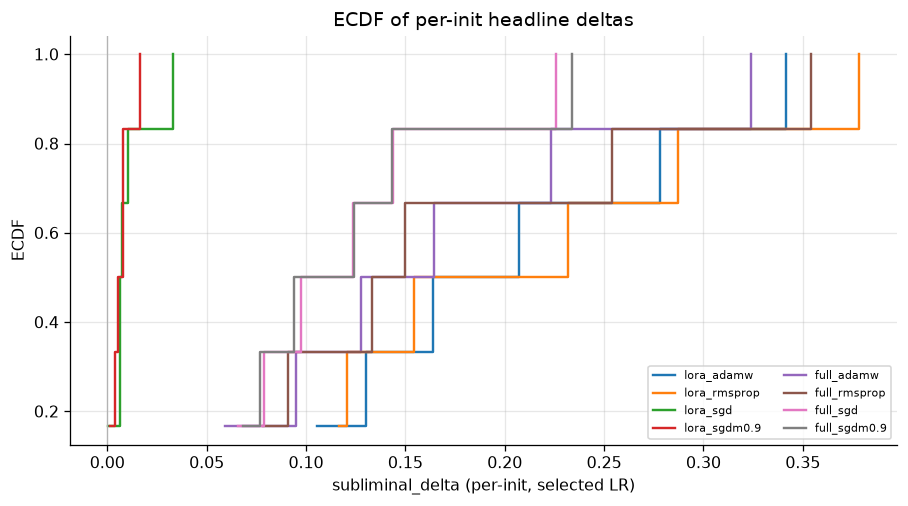

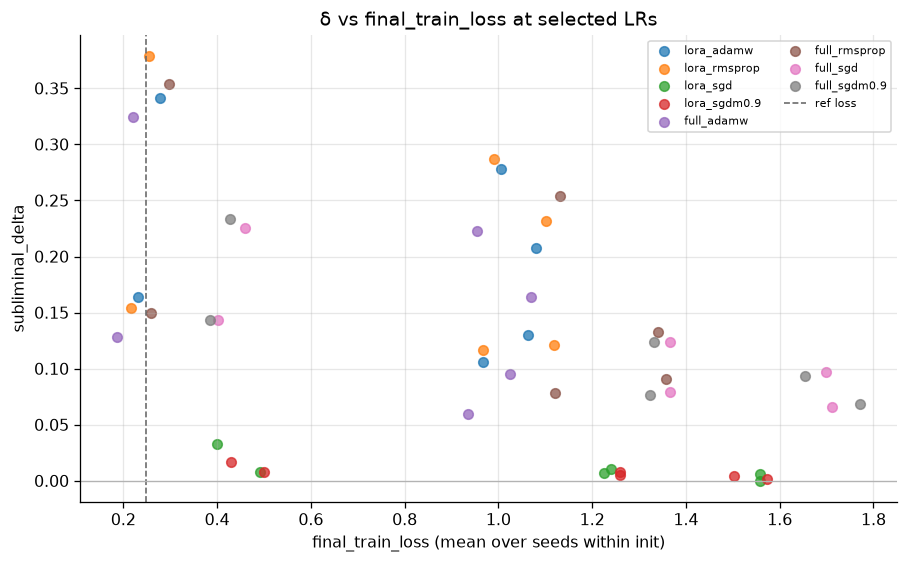

In [61]:
# Rank stability: for each (animal, init), rank arms by δ; count top-1 frequency
ranks = []
for animal in plan.ANIMALS:
    for init in INIT_ORDER:
        sub = head_d[(head_d["animal"] == animal) & (head_d["init"] == init)]
        if sub.empty:
            continue
        order = sub.sort_values("subliminal_delta", ascending=False)["arm"].tolist()
        for rank, arm in enumerate(order, start=1):
            ranks.append({"animal": animal, "init": init, "arm": arm, "rank": rank})
rank_df = pd.DataFrame(ranks)
top1 = rank_df[rank_df["rank"] == 1].groupby("arm").size().reindex(ARM_ORDER, fill_value=0)
print("Times each arm is rank-1 across (animal × init) = 6 slots:")
print(top1.to_string())
print_opt_scope(rank_df, "rank rows")

# ECDF
fig, ax = plt.subplots(figsize=(8, 4.5))
for arm in ARM_ORDER:
    vals = np.sort(head_d[head_d["arm"] == arm]["subliminal_delta"].dropna().to_numpy())
    if len(vals) == 0:
        continue
    y = np.arange(1, len(vals) + 1) / len(vals)
    ax.step(vals, y, where="post", label=arm)
ax.axvline(0, color="0.7", lw=0.8)
ax.set_xlabel("subliminal_delta (per-init, selected LR)")
ax.set_ylabel("ECDF")
ax.legend(fontsize=7, ncol=2)
ax.set_title("ECDF of per-init headline deltas")
fig.tight_layout()
plt.show()

# δ vs loss colored by arm (selected LR leaves)
fig, ax = plt.subplots(figsize=(8, 5))
for arm in ARM_ORDER:
    sub = loss_by[
        (loss_by["arm"] == arm) & np.isclose(loss_by["student_lr"], SELECTED_LRS[arm])
    ]
    ax.scatter(
        sub["final_train_loss"],
        sub["subliminal_delta"],
        label=arm,
        s=36,
        alpha=0.75,
    )
ax.axvline(ref_loss, color="0.4", ls="--", lw=1, label="ref loss")
ax.axhline(0, color="0.7", lw=0.8)
ax.set_xlabel("final_train_loss (mean over seeds within init)")
ax.set_ylabel("subliminal_delta")
ax.legend(fontsize=7, ncol=2)
ax.set_title("δ vs final_train_loss at selected LRs")
fig.tight_layout()
plt.show()


## 14. Takeaways


In [62]:
# Every number below is recomputed from frames in this kernel.

n_head_inits = int(head_d["init"].nunique())
n_head_rows = len(head_d)
c1_v = "supported" if ok1 else "not_supported"
c2_v = "supported" if c2_ok else "not_supported"
c3_v = "supported" if c3_ok else "not_supported"
c4_verdicts = {r["arm"]: r["recomputed_verdict"] for r in c4_rows}
quarantine_rungs = quarantine[quarantine["tier"] == "quarantine"][
    ["arm", "lr"]
].to_dict("records")
infeas = list(calib["lossmatch_infeasible_arms"])

# Best adaptive vs best sgd (mean over animals at headline)
def _mean_delta(arm: str) -> float:
    return float(_arm_rows(delta_agg, arm)["subliminal_delta"].mean())

adaptive_best = max(adaptive, key=_mean_delta)
sgd_best = max(sgd_arms, key=_mean_delta)

contrast_s = ", ".join(f"{k}: {v:.4f}" for k, v in contrasts.items())
max_abs_c = max(abs(v) for v in contrasts.values())
n_pairs_mode = int(head_d["n_pairs"].mode().iloc[0])
lines = [
    "### Takeaways",
    "",
    f"Recomputed from the loaded frames in this notebook (run set `{RUN_SET_ID}`).",
    "",
    f"- **Campaign finished.** `{campaign_done_txt}`. Transitions submit_p0 -> submit_p1 -> submit_p2 -> finalize all present. Phase-0 uses **{int(calib['max_steps'])}-step** calibration; superseded 200-step screen is under `logs/superseded_s200_screen/`.",
    f"- **Headline grid.** {n_head_rows} per-init `test` delta rows at selected LRs after deduping capability-join duplicates ({n_head_inits} inits x {len(plan.ANIMALS)} animals x {len(ARM_ORDER)} arms). Paired CIs use `n_pairs={n_pairs_mode}` student gseeds; teacher ftseeds are pre-averaged inside each gseed.",
    f"- **C1 full FT:** `{c1_v}` — `full_adamw` n_inits_positive={per1}, best_delta={best1:.4f} at lr={SELECTED_LRS['full_adamw']:g}.",
    f"- **C2 LR dependence:** `{c2_v}` — full_adamw ladder_spread={ladder_spread:.4f} > mean_ci_width={mean_ci_width:.4f} ({fa_ladder['student_lr'].nunique()} Phase-1 rungs on screen init).",
    f"- **C3 adaptive:** `{c3_v}` — all of {adaptive} clear controls on >={plan.CLAIM_MIN_INITS} inits, both animals. Strongest mean delta among them: `{adaptive_best}` = {_mean_delta(adaptive_best):.4f}.",
    f"- **C4 SGD:** recomputed per-arm verdicts {c4_verdicts}. Quarantined rungs={quarantine_rungs}. Loss-match infeasible arms={infeas} (report floor, do not call nearest miss matched). Strongest SGD-family mean delta: `{sgd_best}` = {_mean_delta(sgd_best):.4f} vs adamw refs.",
    f"- **C5 interaction:** contrasts={{{contrast_s}}} (max |contrast|={max_abs_c:.4f}). SGD-family effects shrink sharply under LoRA relative to full FT.",
    f"- **Gates.** Control floor passed (max floor={active['floor_p_target'].max():.4f} <= {plan.CONTROL_FLOOR_MAX}, max spread={spread['spread'].max():.4f} <= {plan.CONTROL_FLOOR_MAX_SPREAD}). One quarantine: `lora_sgdm0.9 @ 0.1` (headline LR -> {SELECTED_LRS['lora_sgdm0.9']:g}).",
    f"- **Seeds.** Across-init delta dispersion and gseed CI half-widths are tabulated in section 8b; tfs is not a separate delta axis in `optparam_delta` (pre-averaged). Missing Phase-2 headline leaves: {len(missing_leaves)}.",
    "- **Gaps.** Eval-grade FC `target_share` is absent from `results/*.csv` (probe `fc_share` used instead). Grad concentration is Phase-0-only / correlational. On-disk `optparam_delta_agg` inflates `n_inits_positive` via capability-join duplicates — this notebook recomputes from deduped `optparam_delta`.",
]
print(chr(10).join(lines))


### Takeaways

Recomputed from the loaded frames in this notebook (run set `20260801_optparam_160m`).

- **Campaign finished.** `campaign 20260801_optparam_160m finished 2026-08-02T22:31:07Z`. Transitions submit_p0 -> submit_p1 -> submit_p2 -> finalize all present. Phase-0 uses **625-step** calibration; superseded 200-step screen is under `logs/superseded_s200_screen/`.
- **Headline grid.** 48 per-init `test` delta rows at selected LRs after deduping capability-join duplicates (3 inits x 2 animals x 8 arms). Paired CIs use `n_pairs=3` student gseeds; teacher ftseeds are pre-averaged inside each gseed.
- **C1 full FT:** `supported` — `full_adamw` n_inits_positive={'cat': 3, 'dog': 3}, best_delta=0.2371 at lr=1e-05.
- **C2 LR dependence:** `supported` — full_adamw ladder_spread=0.2114 > mean_ci_width=0.0747 (4 Phase-1 rungs on screen init).
- **C3 adaptive:** `supported` — all of ['lora_adamw', 'lora_rmsprop', 'full_adamw', 'full_rmsprop'] clear controls on >=2 inits, both animals. Stron

## 15. Claims we can make (from this analysis)

**Literature target.** Blank et al. ([arXiv:2606.00995](https://arxiv.org/abs/2606.00995), *Subliminal Learning Is Steering Vector Distillation*) report that **behavioral** SL “only exceeds the reference model’s trait preference under low-rank training and adaptive optimization” (Fig. 7b), that full finetuning fails to induce trait affinity beyond the reference, and that plain SGD fails while Adam/RMSProp succeed (Fig. 7c; Appendix L still finds loss-matched SGD fails). Their concurrent note that SGD *can* work with HP tuning was not replicated in their setting. (Appendix K separately finds *steering-vector distillation* under full FT at LR 1e-5 — mechanism ≠ behavior.) This campaign (`20260801_optparam_160m`; plan `optimizer_parameterization_campaign_c092f671`; E8×E11 in `MECHANISTIC_SL_EXPERIMENT_PLAN`) tests those **behavioral** claims under **on-policy GKD / PolyPythia-160M** with **per-arm screened LRs** — a different setting than Blank’s off-policy SFT / 7–8B shared-LR ablations.

**Primary metric here:** `subliminal_delta` on held-out `test` / `prob`, recomputed in §12–§14 from deduped frames (not re-derived from raw preference leaves).

### Supported claims (recomputed)

1. **Full FT does induce SL here (challenges Blank Fig. 7b’s behavioral full-FT null).**  
   **C1 supported:** `full_adamw` clears matched controls on ≥2/3 inits, both animals (`n_inits_positive` cat=3, dog=3; best δ≈0.237 at LR 1e-5). **Figs:** §5 headline heatmap; §8 init strips; §12 C1.

2. **The full-FT effect is LR-dependent (Blank Fig. 7b/c omit per-optimizer LRs).**  
   **C2 supported:** Phase-1 `full_adamw` ladder spread ≈0.211 > mean within-rung CI width ≈0.075 (4 rungs on screen init). **Figs:** §4 dose-response; §2 calibration ladder; §12 C2.

3. **Adaptive optimizers work under *both* LoRA and full FT.**  
   **C3 supported:** `lora_adamw`, `lora_rmsprop`, `full_adamw`, `full_rmsprop` all clear controls. Strongest adaptive mean δ among them: `lora_rmsprop` ≈0.215; headline cells peak at `lora_rmsprop` cat δ≈0.299. **Figs:** §5 heatmap; §13 rank stability (`lora_rmsprop` top-1 in 4/6 animal×init slots); §12 C3.

4. **Optimizer × parameterization interaction is large for the SGD family.**  
   **C5 measured:** contrasts vs AdamW — rmsprop ≈+0.014, sgd ≈−0.162, sgdm0.9 ≈−0.172. SGD-family effects **shrink sharply under LoRA** relative to full FT. **Figs:** §12 C5 bar chart; §5 (full SGD/SGDm δ≈0.10–0.14 vs LoRA SGD/SGDm ≈0.006–0.015); §10 probe `fc_share` (LoRA SGD/SGDm much weaker).

### What we cannot claim cleanly

5. **Not a Blank-style “SGD is null” under the prereg equivalence rule (C4).**  
   Recomputed per-arm: `full_sgd` / `full_sgdm0.9` / `lora_sgd` = `effect_present`; `lora_sgdm0.9` = `inconclusive` (disk said `effect_present`; quarantine demoted LR 0.1→0.01). **Zero** arms `null_bounded` at the 5%×AdamW equivalence bound. So we **do not** endorse “SGD fails” as in Blank Fig. 7c / App. L — but see caveats below. **Figs:** §12 C4 table; §4–§5.

6. **Loss-matched SGD comparison to AdamW is unavailable for the SGD family.**  
   Phase-0 marked `full_sgd`, `full_sgdm0.9`, `lora_sgd`, `lora_sgdm0.9` **lossmatch_infeasible** (closest rel. loss errors ~0.57–0.96). §6 therefore cannot reproduce Blank App. L’s loss-matched Adam-vs-SGD panel for those arms. **Figs:** §2 †infeas markers; §6.

7. **Some full-SGD “successes” look capability-risky.**  
   §9 flags high δ with `perplexity_ratio`>3 mainly on full SGD/SGDm/rmsprop (esp. `original` init) — treat those cells as guarded, not clean SL wins.

### Scope limits (do not overclaim)

- Setting differs from Blank (on-policy GKD, 160M, screened LRs) — agreement/disagreement is scoped, not a literal Fig. 7 replication.  
- Control floor passed; one quarantine (`lora_sgdm0.9 @ 0.1`); Phase-2 headline grid complete (0 missing leaves).  
- Eval-grade FC `target_share` absent from `results/*.csv` (§10 uses probe `fc_share` only).  
- Grad concentration (§11) is Phase-0 / correlational — no causal claim.  
- Numbers above are from §14’s recomputation; on-disk `optparam_delta_agg` can inflate `n_inits_positive` via capability-join duplicates.

**Bottom line.** Against Blank’s behavioral story that SL needs LoRA+adaptive optimizers and that full FT / SGD fail: **this campaign supports full-FT SL and adaptive SL under both parameterizations when LRs are screened (C1–C3), measures a strong LoRA×SGD collapse (C5), and does *not* establish an SGD null under the prereg equivalence test (C4)** — with the important qualification that SGD-family loss-match failed and some full-SGD cells fail the perplexity guardrail.